# Турбокод: два слабых кода, которые договариваются

В 1993 году Берру, Главьё и Титимаджима показали код, работающий в 0.5 дБ от предела Шеннона, — до этого считалось, что практические коды отстают на 3 дБ и больше. Идея в двух частях:

1. **Кодер**: два одинаковых простых **рекурсивных свёрточных** кодера (RSC) кодируют один и тот же блок $K$ бит — первый в исходном порядке, второй в переставленном **перемежителем** $\Pi$. Передаются систематические биты и обе последовательности проверок: $R\approx1/3$. Каждый кодер в отдельности слабый (8 состояний, $d_\text{free}$ маленький), но слово малого веса должно быть «лёгким» для **обоих** одновременно, а перемежитель делает это редкостью.
2. **Декодер**: оптимально декодировать всё вместе невозможно (решётка из $2^K$ состояний). Вместо этого каждый кодер декодируется **оптимально в одиночку** — алгоритмом BCJR (MAP по решётке), — и декодеры по очереди передают друг другу **внешнюю** (extrinsic) информацию о битах:
$$L_\text{post}=\underbrace{L_\text{ch}}_{\text{канал}}+\underbrace{L_a}_{\text{от соседа}}+\underbrace{L_e}_{\text{новое: из своих проверок}},\qquad\text{соседу отдаётся только }L_e.$$
Это тот же принцип, что у BP в LDPC (соседний ноутбук), только «узлов-проверок» два, и каждый — целый свёрточный код.

В LTE (36.212 §5.1.3) турбокод с $g_0=13_8$, $g_1=15_8$ и QPP-перемежителем кодирует все данные; в 5G NR его сменил LDPC. Здесь — всё по шагам, затем код $K=1024$ в работе.

**Как устроен ноутбук.**
- *Часть I — устройство по шагам* (разделы 1–7): почему рекурсивный код, решётка и хвост, турбокодер и перемежитель (и почему он решает всё), вывод BCJR с проверкой полным перебором, $\max^*$ и max-log, внешняя информация и «эхо», турбо-итерации вручную на блоке из 40 бит.
- *Часть II — $K=1024$ в деле* (разделы 8–13): итерации изнутри, EXIT-диаграмма и порог, водопад BER/FER, роль перемежителя, длина блока, сравнение с LDPC.

Параметры — в ячейке ниже, всё остальное перезапускается от них.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
from scipy.integrate import quad
from scipy.optimize import brentq

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
K_TURBO = 1024     # длина блока (QPP есть для 40, 512, 1024, 2048, 6144)
ITERS = 8          # полных итераций (каждая — два BCJR)
EBN0_DB = 0.5      # рабочая точка разделов 5–9 (водопад R=1/3 при K=1024 — 0.25…1 дБ)
SCALE_ML = 0.7     # масштаб внешней информации для max-log-MAP

rng = np.random.default_rng(SEED)

## Примитивы: QPP, RSC и решётка, турбокодер, BCJR, турбодекодер, канал, J-функция
| функция | что делает | раздел |
|---|---|---|
| `NXT`, `PAR`, `FB`, `PREV_S/U` | таблицы решётки RSC: следующее состояние, проверочный бит, вход хвоста, рёбра в состояние | 1, 2 |
| `rsc_encode`, `turbo_encode` | RSC с терминированием; параллельная конкатенация через $\Pi$ | 2, 3 |
| `qpp` | перемежитель $\Pi(i)=(f_1i+f_2i^2)\bmod K$ | 3 |
| `bcjr`, `maxstar` | MAP-декодер одного RSC: log-MAP / max-log-MAP | 4, 5 |
| `turbo_decode` | обмен внешней информацией, ранний останов, флаг `extrinsic` | 6–13 |
| `channel`, `puncture_half` | BPSK + AWGN → LLR, выкалывание до $R\approx1/2$ | 4, 13 |
| `mi`, `J`, `biawgn_limit` | взаимная информация, EXIT, предел Шеннона | 9, 10 |

In [2]:
# ---------- QPP-перемежитель (36.212, табл. 5.1.3-3) ----------
QPP = {40: (3, 10), 512: (31, 64), 1024: (31, 64), 2048: (31, 64), 6144: (263, 480)}

def qpp(K):
    """Квадратичный перестановочный перемежитель Π(i) = (f1·i + f2·i²) mod K."""
    f1, f2 = QPP[K]
    i = np.arange(K, dtype=np.int64)
    return (f1 * i + f2 * i * i) % K

# ---------- RSC: G(D) = [1, g1/g0], g0 = 1+D²+D³ (13₈) — обратная связь, g1 = 1+D+D³ (15₈) ----------
NXT = np.zeros((8, 2), int); PAR = np.zeros((8, 2), int); FB = np.zeros(8, int)
for s in range(8):
    s1, s2, s3 = (s >> 2) & 1, (s >> 1) & 1, s & 1          # состояние = содержимое регистра (s1 — свежий)
    FB[s] = s2 ^ s3                                           # вход, гасящий обратную связь → хвост
    for u in (0, 1):
        a = u ^ s2 ^ s3                                       # бит, вдвигаемый в регистр
        NXT[s, u] = (a << 2) | (s1 << 1) | s2
        PAR[s, u] = a ^ s1 ^ s3
PREV_S = np.zeros((8, 2), int); PREV_U = np.zeros((8, 2), int)   # в каждое состояние ведут ровно 2 ребра
_c = np.zeros(8, int)
for s in range(8):
    for u in (0, 1):
        ns = NXT[s, u]; PREV_S[ns, _c[ns]] = s; PREV_U[ns, _c[ns]] = u; _c[ns] += 1

def rsc_encode(u):
    """u (B,K) → проверка z (B,K), хвост: систематика xt (B,3) и проверка zt (B,3)."""
    B, K = u.shape
    s = np.zeros(B, int); z = np.empty((B, K), int)
    for k in range(K):
        z[:, k] = PAR[s, u[:, k]]; s = NXT[s, u[:, k]]
    xt = np.empty((B, 3), int); zt = np.empty((B, 3), int)
    for k in range(3):                                        # терминирование в нулевое состояние
        ut = FB[s]; xt[:, k] = ut; zt[:, k] = PAR[s, ut]; s = NXT[s, ut]
    return z, xt, zt

def turbo_encode(u, pi=None):
    """u (B,K) → (B, 3K+12): тройки [систематика, проверка 1, проверка 2] и 12 хвостовых бит. R ≈ 1/3."""
    pi = qpp(u.shape[1]) if pi is None else pi
    z1, xt1, zt1 = rsc_encode(u)
    z2, xt2, zt2 = rsc_encode(u[:, pi])
    return np.concatenate([np.stack([u, z1, z2], -1).reshape(len(u), -1), xt1, zt1, xt2, zt2], 1)

def maxstar(a, b, exact=True):
    """max*(a,b) = ln(eᵃ + eᵇ) = max(a,b) + ln(1 + e^−|a−b|); max-log выбрасывает поправку."""
    m = np.maximum(a, b)
    return m + np.log1p(np.exp(-np.abs(a - b))) if exact else m

def bcjr(Ls, Lp, La, Lst, Lpt, exact=True, trace=None):
    """MAP-декодер RSC (log-MAP или max-log-MAP) по решётке с хвостом. LLR = ln P(0)/P(1), (B,K).
    trace — словарь: сюда кладутся γ, α, β (для разбора по шагам)."""
    B, K = Ls.shape
    Lx = np.concatenate([Ls + La, Lst], 1).T; Lz = np.concatenate([Lp, Lpt], 1).T
    zs = 1 - 2 * PAR; xs = np.array([1, -1])
    g = 0.5 * (Lx[:, :, None, None] * xs + Lz[:, :, None, None] * zs)     # γ_t(s,u): (T,B,8,2)
    T = K + 3
    al = np.full((T + 1, B, 8), -1e9); al[0, :, 0] = 0                    # старт из нуля
    for t in range(T):
        a = maxstar(al[t][:, PREV_S[:, 0]] + g[t][:, PREV_S[:, 0], PREV_U[:, 0]],
                    al[t][:, PREV_S[:, 1]] + g[t][:, PREV_S[:, 1], PREV_U[:, 1]], exact)
        al[t + 1] = a - a.max(1, keepdims=True)                           # нормировка: важны только разности
    be = np.full((B, 8), -1e9); be[:, 0] = 0                              # финиш в нуле (хвост)
    bes = np.empty((T + 1, B, 8)); bes[T] = be
    Lout = np.empty((B, K))
    red = (lambda v: np.logaddexp.reduce(v, 1)) if exact else (lambda v: v.max(1))
    for t in range(T - 1, -1, -1):
        if t < K:
            m = al[t][:, :, None] + g[t] + be[:, NXT]                     # α_t(s) + γ_t(s,u) + β_{t+1}(s')
            Lout[:, t] = red(m[:, :, 0]) - red(m[:, :, 1])
        b = maxstar(be[:, NXT[:, 0]] + g[t][:, :, 0], be[:, NXT[:, 1]] + g[t][:, :, 1], exact)
        be = b - b.max(1, keepdims=True); bes[t] = be
    if trace is not None:
        trace.update(g=g, al=al, be=bes)
    return Lout

def turbo_decode(L, K, iters=ITERS, exact=True, scale=SCALE_ML, cb=None, pi=None, extrinsic=True, early=True):
    """Итеративный декодер: два BCJR обмениваются внешней информацией через перемежитель.
    Возвращает решения (B,K) и число итераций на кадр. Ранний останов: кадр замораживается,
    когда жёсткие решения обоих декодеров совпали.
    cb(it, d) получает словарь LLR этой итерации (всё в естественном порядке бит).
    extrinsic=False — ошибка нарочно: соседу отдаётся апостериорный LLR без вычета его же вклада."""
    B = len(L)
    m = L[:, :3 * K].reshape(-1, K, 3); t = L[:, 3 * K:]
    Ls, Lp1, Lp2 = m[..., 0], m[..., 1], m[..., 2]
    pi = qpp(K) if pi is None else pi
    ipi = np.argsort(pi)
    sc = 1.0 if exact else scale
    A1, L1, Le1, L2, Le2 = (np.zeros((B, K)) for _ in range(5))
    n_it = np.full(B, iters); act = np.arange(B)
    for it in range(iters):
        a = act
        l1 = bcjr(Ls[a], Lp1[a], Le2[a], t[a, 0:3], t[a, 3:6], exact)           # априори декодера 1 = внешнее от 2
        le1 = sc * (l1 - Ls[a] - Le2[a]) if extrinsic else l1 - Ls[a]
        l2 = bcjr(Ls[a][:, pi], Lp2[a], le1[:, pi], t[a, 6:9], t[a, 9:12], exact)   # декодер 2 работает в порядке Π
        le2 = sc * (l2 - Ls[a][:, pi] - le1[:, pi]) if extrinsic else l2 - Ls[a][:, pi]
        A1[a], L1[a], Le1[a], L2[a], Le2[a] = Le2[a], l1, le1, l2[:, ipi], le2[:, ipi]
        if cb: cb(it, dict(La1=A1, L1=L1, Le1=Le1, L2=L2, Le2=Le2))
        if early:
            done = ((l1 < 0) == (L2[a] < 0)).all(1)
            n_it[a[done]] = it + 1; act = a[~done]
            if len(act) == 0: break
    return (L2 < 0).astype(int), n_it

def channel(c, ebn0_db, R, rng, mask=None):
    """BPSK + AWGN → LLR 2y/σ². mask — какие биты переданы (выколотые получают LLR = 0)."""
    s2 = 1 / (2 * R * 10 ** (ebn0_db / 10))
    L = 2 * ((1 - 2.0 * c) + np.sqrt(s2) * rng.standard_normal(c.shape)) / s2
    if mask is not None: L[:, ~mask] = 0
    return L

def puncture_half(K):
    """Маска R≈1/2: проверки двух кодеров выкалываются через одну."""
    m = np.ones((K, 3), bool); m[1::2, 1] = False; m[0::2, 2] = False
    return np.r_[m.ravel(), np.ones(12, bool)]

def mi(L, x):
    """Взаимная информация между LLR и битом x∈{±1}: I = 1 − E[log2(1 + e^{−xL})]."""
    return 1 - np.mean(np.logaddexp(0, -x * L)) / np.log(2)

# J(σ): информация в гауссовом LLR ~ N(σ²/2, σ²)
_t, _w = np.polynomial.hermite.hermgauss(120)
_S = np.linspace(0, 25, 5001)
_J = np.maximum.accumulate([1 - np.sum(_w * np.logaddexp(0, -(s * s / 2 + np.sqrt(2) * s * _t))) / np.sqrt(np.pi) / np.log(2) for s in _S])
J = lambda s: np.interp(s, _S, _J)
Jinv = lambda I: np.interp(I, _J, _S)

def biawgn_limit(R):
    """Eb/N0 (дБ), при котором ёмкость BPSK-AWGN равна R."""
    return brentq(lambda e: J(np.sqrt(8 * R * 10 ** (e / 10))) - R, -3, 10)

# самопроверки
assert all(len(np.unique(qpp(K))) == K for K in QPP), "QPP не перестановка"
_u = rng.integers(0, 2, (4, 40)); _c = turbo_encode(_u)
assert np.all(turbo_decode(4.0 * (1 - 2 * _c), 40)[0] == _u)
R3 = K_TURBO / (3 * K_TURBO + 12)
print(f"K = {K_TURBO}, n = {3 * K_TURBO + 12}, R = {R3:.4f}; Шеннон для BPSK при R = 1/3: {biawgn_limit(1/3):.2f} дБ, при R = 1/2: {biawgn_limit(1/2):.2f} дБ")

K = 1024, n = 3084, R = 0.3320; Шеннон для BPSK при R = 1/3: -0.50 дБ, при R = 1/2: 0.19 дБ


# Часть I. Устройство по шагам

## 1. Свёрточный код: почему рекурсивный
Свёрточный кодер — регистр сдвига из $\nu=3$ ячеек (8 состояний) и XOR-ы. Удобно писать через полиномы от задержки $D$:
- **нерекурсивный** (NSC): выходы $y_j(D)=u(D)\,g_j(D)$ — КИХ-фильтры над GF(2). Одиночная единица на входе даёт выход длиной $\nu+1$ — **конечный** отклик;
- **рекурсивный систематический** (RSC, LTE): $x=u$, проверка $z(D)=u(D)\,\dfrac{g_1(D)}{g_0(D)}$, $g_0=1+D^2+D^3$ (обратная связь), $g_1=1+D+D^3$. Деление на $g_0$ — это БИХ-фильтр: отклик на одиночную единицу **бесконечен** и периодичен. $g_0$ — примитивный полином степени 3, поэтому период $2^3-1=7$.

**Почему это важно.** Вход веса 1 у RSC даёт проверку бесконечного (в блоке — огромного) веса. Конечный отклик дают только входы, делящиеся на $g_0$, — самый лёгкий из них $1+D^7$ (две единицы на расстоянии 7, т.к. $g_0\,|\,1+D^7$). Значит, слова малого веса у RSC порождаются входами **веса ≥ 2 со специальной структурой**. Перемежитель её разрушает для второго кодера (раздел 3). У NSC же любой вход малого веса даёт малый вес — перемежитель не помог бы.

Слева — импульсные отклики, в центре — проверка RSC на вход $1+D^d$, справа — вес проверки (в окне 64 бит, без терминирования).

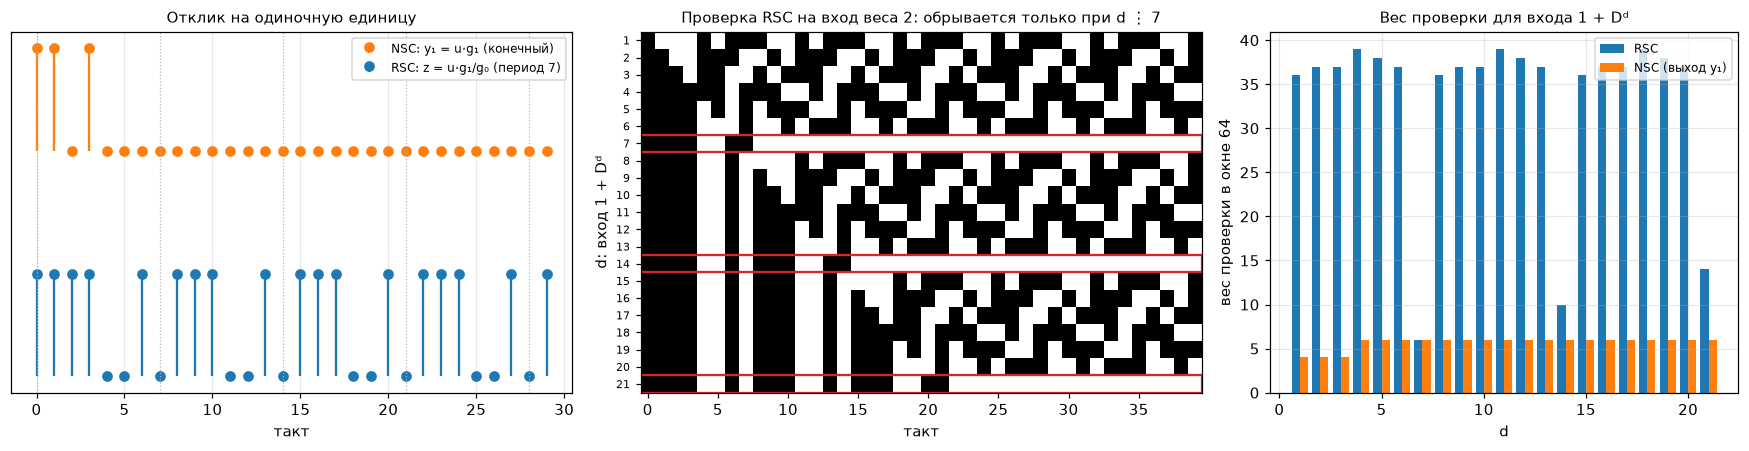

отклик RSC на 1:   1111001011100101110010 … период 7
(1 + D⁷) mod g₀ = [0, 0, 0] → g₀ делит 1 + D⁷;  (1 + D⁵) mod g₀ = [0, 1, 0]
вес проверки RSC на 1 + D⁷: 6, на 1 + D⁵: 38 (и растёт с длиной окна)


In [3]:
def nsc_encode(u, taps=([1, 0, 1, 1], [1, 1, 0, 1])):
    # нерекурсивный (13₈, 15₈): два КИХ-фильтра над GF(2); коэффициенты при D⁰..D³
    return [np.array([np.convolve(r, t)[:u.shape[1]] % 2 for r in u]) for t in taps]

Lw = 64
imp = np.zeros((1, Lw), int); imp[0, 0] = 1
y0, y1 = nsc_encode(imp)
z_imp = rsc_encode(imp)[0][0]
ds = np.arange(1, 22)
U2 = np.zeros((len(ds), Lw), int); U2[:, 0] = 1; U2[np.arange(len(ds)), ds] = 1
Z2 = rsc_encode(U2)[0]
w_nsc = nsc_encode(U2)[1].sum(1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
n_show = 30
ax[0].stem(np.arange(n_show), y1[0, :n_show] + 2.2, linefmt="C1-", markerfmt="C1o", basefmt=" ", bottom=2.2, label="NSC: y₁ = u·g₁ (конечный)")
ax[0].stem(np.arange(n_show), z_imp[:n_show], linefmt="C0-", markerfmt="C0o", basefmt=" ", label="RSC: z = u·g₁/g₀ (период 7)")
for k in range(0, n_show, 7): ax[0].axvline(k, color="0.7", ls=":", lw=0.8)
ax[0].set_yticks([]); ax[0].set_xlabel("такт"); ax[0].legend(fontsize=8, loc="upper right"); ax[0].set_title("Отклик на одиночную единицу", fontsize=10)
ax[1].imshow(Z2[:, :40], cmap="Greys", aspect="auto", interpolation="nearest"); ax[1].grid(False)
ax[1].set_yticks(range(len(ds))); ax[1].set_yticklabels(ds, fontsize=7); ax[1].set_ylabel("d: вход 1 + Dᵈ"); ax[1].set_xlabel("такт")
for d in (7, 14, 21): ax[1].add_patch(plt.Rectangle((-0.5, d - 1.5), 40, 1, fill=False, ec="C3", lw=1.5))
ax[1].set_title("Проверка RSC на вход веса 2: обрывается только при d ⋮ 7", fontsize=10)
ax[2].bar(ds - 0.2, Z2.sum(1), 0.4, color="C0", label="RSC")
ax[2].bar(ds + 0.2, w_nsc, 0.4, color="C1", label="NSC (выход y₁)")
ax[2].set_xlabel("d"); ax[2].set_ylabel(f"вес проверки в окне {Lw}"); ax[2].legend(fontsize=8); ax[2].set_title("Вес проверки для входа 1 + Dᵈ", fontsize=10)
plt.tight_layout(); plt.show()

def gf2_mod(a, b):                                # остаток от деления полиномов над GF(2), коэффициенты от D⁰
    a = list(a)
    while len(a) >= len(b):
        if a[-1]:
            for i in range(len(b)): a[len(a) - len(b) + i] ^= b[i]
        a.pop()
    return a
print("отклик RSC на 1:  ", "".join(map(str, z_imp[:22])), "… период", next(p for p in range(1, 20) if np.array_equal(z_imp[10:30], z_imp[10 + p:30 + p])))
print("(1 + D⁷) mod g₀ =", gf2_mod([1, 0, 0, 0, 0, 0, 0, 1], [1, 0, 1, 1]), "→ g₀ делит 1 + D⁷;  (1 + D⁵) mod g₀ =", gf2_mod([1, 0, 0, 0, 0, 1], [1, 0, 1, 1]))
print(f"вес проверки RSC на 1 + D⁷: {Z2[6].sum()}, на 1 + D⁵: {Z2[4].sum()} (и растёт с длиной окна)")

## 2. Решётка и терминирование
Состояние кодера $s=(s_1s_2s_3)$ — содержимое регистра, $2^3=8$ состояний. Каждый такт вход $u$ переводит $s\to s'$ и выдаёт проверочный бит $z$:
$$a=u\oplus s_2\oplus s_3\ (\text{обратная связь }g_0),\qquad s'=(a,\,s_1,\,s_2),\qquad z=a\oplus s_1\oplus s_3\ (g_1).$$
Развернув переходы во времени, получаем **решётку**: каждый путь из состояния 0 — одно кодовое слово, а из каждого состояния выходят и в каждое входят ровно два ребра (`NXT`, `PREV_S`). Декодер BCJR — это проход по решётке вперёд и назад.

**Терминирование.** Чтобы решётка кончалась в известном состоянии 0, после данных подаём 3 **хвостовых** бита. У рекурсивного кодера это не нули: нужно погасить обратную связь, $u=s_2\oplus s_3$ (таблица `FB`), тогда $a=0$ и регистр за 3 такта обнуляется. Хвостовые биты не данные, но передаются (по 3 систематических и 3 проверочных на кодер), иначе последние биты блока защищены хуже.

Ниже — решётка и путь для входа `1 0 1 1 0 0 1 0` плюс хвост. Сплошные рёбра — $u=0$, пунктир — $u=1$; подписи на пути — $u/z$.

 s  (s1s2s3) | u=0: s' z | u=1: s' z | хвост u
 0   000      |    0  0  |    4  1  |   0
 1   001      |    4  0  |    0  1  |   1
 2   010      |    5  1  |    1  0  |   1
 3   011      |    1  1  |    5  0  |   0
 4   100      |    2  1  |    6  0  |   0
 5   101      |    6  1  |    2  0  |   1
 6   110      |    7  0  |    3  1  |   1
 7   111      |    3  0  |    7  1  |   0


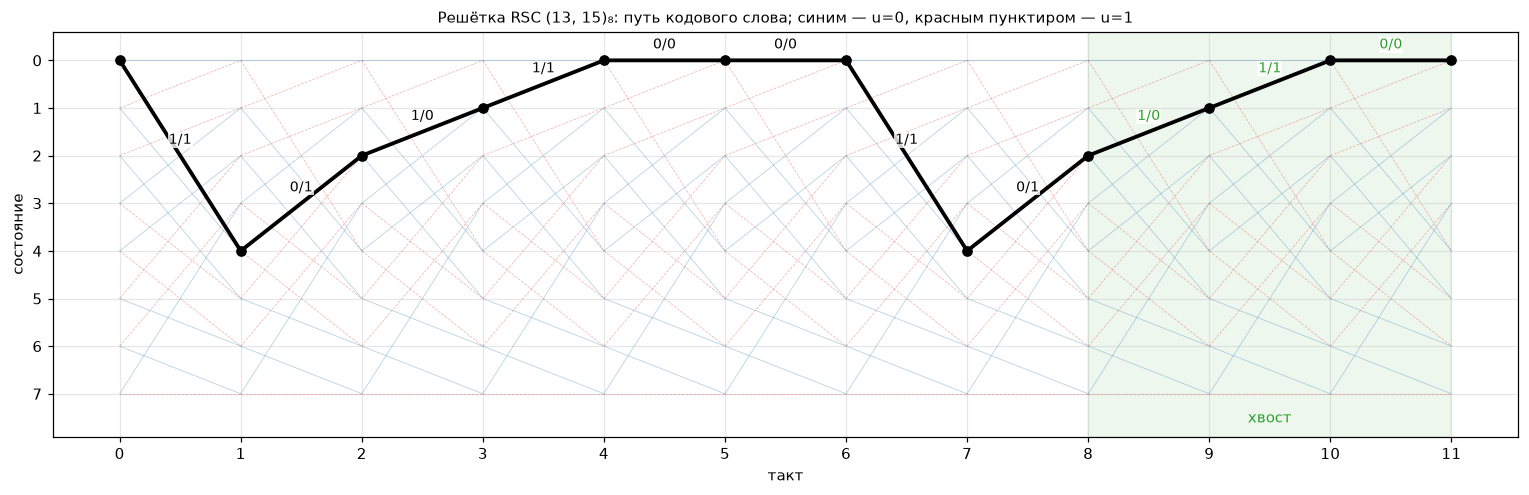


данные [1 0 1 1 0 0 1 0] → проверка [1 1 0 1 0 0 1 1]; хвост: u = [1 1 0], z = [0 1 0]; конечное состояние 0
rsc_encode: z = [1 1 0 1 0 0 1 1], хвост x = [1 1 0], z = [0 1 0] — совпадает: True


In [4]:
print(" s  (s1s2s3) | u=0: s' z | u=1: s' z | хвост u")
for s in range(8):
    print(f" {s}   {s >> 2 & 1}{s >> 1 & 1}{s & 1}      |    {NXT[s, 0]}  {PAR[s, 0]}  |    {NXT[s, 1]}  {PAR[s, 1]}  |   {FB[s]}")

u_ex = np.array([1, 0, 1, 1, 0, 0, 1, 0])
s, path, inp, par = 0, [0], [], []
for b in u_ex:
    inp.append(b); par.append(PAR[s, b]); s = NXT[s, b]; path.append(s)
for _ in range(3):
    b = FB[s]; inp.append(b); par.append(PAR[s, b]); s = NXT[s, b]; path.append(s)
z_c, xt_c, zt_c = rsc_encode(u_ex[None])

T_ex = len(inp)
fig, a = plt.subplots(figsize=(14, 4.6))
for t in range(T_ex):
    for s in range(8):
        for b in (0, 1):
            a.plot([t, t + 1], [s, NXT[s, b]], color="C0" if b == 0 else "C3", ls="-" if b == 0 else "--", lw=0.5, alpha=0.35)
a.plot(range(T_ex + 1), path, "k-o", lw=2.5, ms=6)
for t in range(T_ex):
    a.text(t + 0.5, (path[t] + path[t + 1]) / 2 - 0.25, f"{inp[t]}/{par[t]}", ha="center", fontsize=9,
           color="C2" if t >= len(u_ex) else "k", bbox=dict(fc="w", ec="none", alpha=0.8, pad=0.5))
a.axvspan(len(u_ex), T_ex, color="C2", alpha=0.08); a.text(len(u_ex) + 1.5, 7.6, "хвост", color="C2", ha="center")
a.set_ylim(7.9, -0.6); a.set_yticks(range(8)); a.set_ylabel("состояние"); a.set_xticks(range(T_ex + 1)); a.set_xlabel("такт")
a.set_title("Решётка RSC (13, 15)₈: путь кодового слова; синим — u=0, красным пунктиром — u=1", fontsize=10)
plt.tight_layout(); plt.show()
print(f"\nданные {u_ex} → проверка {np.array(par[:8])}; хвост: u = {np.array(inp[8:])}, z = {np.array(par[8:])}; конечное состояние {path[-1]}")
print(f"rsc_encode: z = {z_c[0]}, хвост x = {xt_c[0]}, z = {zt_c[0]} — совпадает: {np.array_equal(z_c[0], par[:8]) and np.array_equal(xt_c[0], inp[8:])}")

## 3. Турбокодер и QPP-перемежитель
$$\mathbf u\ \longrightarrow\ \big[\ \mathbf u,\ \ \mathbf z_1=\text{RSC}(\mathbf u),\ \ \mathbf z_2=\text{RSC}(\Pi\mathbf u)\ \big]+12\text{ хвостовых бит},\qquad R=\frac{K}{3K+12}.$$
Систематика второго кодера не передаётся — это те же биты в другом порядке.

**Зачем перемежитель.** Слово малого веса требует, чтобы **обе** проверки были лёгкими. Из раздела 1: $\mathbf z_1$ лёгкая, только если вход — пары единиц на расстоянии, кратном 7 (и их комбинации). Хороший $\Pi$ разносит такие пары далеко: если после перестановки расстояние не кратно 7, $\mathbf z_2$ тянется до конца блока; если кратно, $7m$ с большим $m$, то вес $\mathbf z_2$ всё равно растёт с $m$ (вход $1+D^{7m}$ даёт проверку длины $\approx7m$). Плохо только, когда пара остаётся **близкой**. Без перемежителя ($\Pi=$ тождество) обе проверки одинаковы, и выигрыша нет.

**QPP** (quadratic permutation polynomial): $\Pi(i)=(f_1i+f_2i^2)\bmod K$. Почему не случайная перестановка:
- задаётся двумя числами на каждый из 188 размеров $K$ — не надо хранить таблицу;
- **без конфликтов памяти**: если разрезать блок на $M$ окон для параллельных BCJR, все окна в каждый такт обращаются в разные банки — основа быстрых декодеров LTE;
- алгебраическая структура гарантирует хороший **разнос** близких бит (случайная перестановка иногда сводит их вместе).

Ниже: слева — сама перестановка для $K=40$; в центре — куда уходят пары $(i,i+7)$ при $K$ = `K_TURBO` (доля «кратных 7» у QPP такая же, как у случайного, но **ни одна** пара не сближается: минимум 25 против 1); справа — полный вес кодовых слов, порождённых **всеми** входами веса 2 вида $1+D^{7m}$ ($m\le7$), для трёх перемежителей.

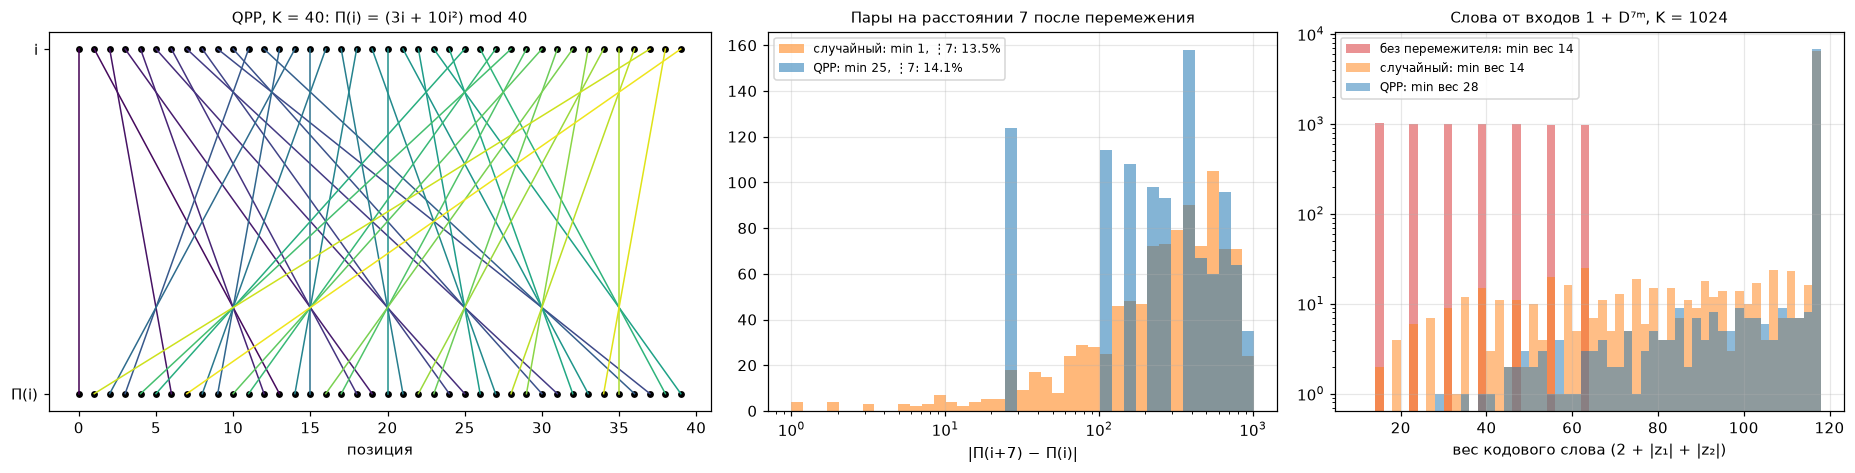

без перемежителя : минимальный вес  14, слов веса < 30:  2027 из 6972
случайный        : минимальный вес  14, слов веса < 30:    19 из 6972
QPP              : минимальный вес  28, слов веса < 30:     1 из 6972

K = 40: вход с единицами в 5 и 12 (1 + D⁷) → Π переносит их в [25 36] (расстояние 11); вес z₁ = 6, z₂ = 14
длина слова: 3·1024 + 12 = 3084, R = 0.3320


In [5]:
K3 = K_TURBO
pis = {"без перемежителя": np.arange(K3), "случайный": np.random.default_rng(0).permutation(K3), "QPP": qpp(K3)}
pairs = np.array([(i, i + d) for d in range(7, 50, 7) for i in range(K3 - d)])
U2 = np.zeros((len(pairs), K3), np.int8); U2[np.arange(len(pairs)), pairs[:, 0]] = 1; U2[np.arange(len(pairs)), pairs[:, 1]] = 1
wts = {name: turbo_encode(U2, p).sum(1) for name, p in pis.items()}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
p40 = qpp(40)
for i in range(40):
    ax[0].plot([i, p40[i]], [1, 0], color=plt.cm.viridis(i / 40), lw=1)
ax[0].scatter(range(40), np.ones(40), s=12, c="k"); ax[0].scatter(range(40), np.zeros(40), s=12, c="k")
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Π(i)", "i"]); ax[0].set_xlabel("позиция"); ax[0].grid(False)
ax[0].set_title(f"QPP, K = 40: Π(i) = ({QPP[40][0]}i + {QPP[40][1]}i²) mod 40", fontsize=10)
i7 = np.arange(K3 - 7)
for name, col in [("случайный", "C1"), ("QPP", "C0")]:
    p = pis[name]; sep = np.abs(p[i7 + 7] - p[i7])
    ax[1].hist(sep, np.logspace(0, np.log10(K3), 40), alpha=0.55, color=col,
               label=f"{name}: min {sep.min()}, ⋮7: {np.mean(sep % 7 == 0):.1%}")
ax[1].set_xscale("log"); ax[1].set_xlabel("|Π(i+7) − Π(i)|"); ax[1].legend(fontsize=8); ax[1].set_title("Пары на расстоянии 7 после перемежения", fontsize=10)
bins = np.arange(10, 120, 2)
for (name, w), col in zip(wts.items(), ["C3", "C1", "C0"]):
    ax[2].hist(np.minimum(w, 118), bins, alpha=0.5, color=col, label=f"{name}: min вес {w.min()}")
ax[2].set_yscale("log"); ax[2].set_xlabel("вес кодового слова (2 + |z₁| + |z₂|)"); ax[2].legend(fontsize=8)
ax[2].set_title(f"Слова от входов 1 + D⁷ᵐ, K = {K3}", fontsize=10)
plt.tight_layout(); plt.show()

for name, w in wts.items():
    print(f"{name:17s}: минимальный вес {w.min():3d}, слов веса < 30: {np.sum(w < 30):5d} из {len(w)}")
u_t = np.zeros((1, 40), int); u_t[0, [5, 12]] = 1
c_t = turbo_encode(u_t)
print(f"\nK = 40: вход с единицами в 5 и 12 (1 + D⁷) → Π переносит их в {p40[[5, 12]]} (расстояние {abs(p40[12] - p40[5])}); "
      f"вес z₁ = {c_t[0, 1:120:3].sum()}, z₂ = {c_t[0, 2:120:3].sum()}")
print(f"длина слова: 3·{K_TURBO} + 12 = {3 * K_TURBO + 12}, R = {R3:.4f}")

## 4. BCJR: оптимальный декодер одного свёрточного кода
Нужно для каждого бита $P(u_t\,|\,\mathbf y)$ — сумма вероятностей всех путей решётки с данным $u_t$. Путей $2^K$, но марковость кодера даёт факторизацию: вероятность ребра $s\to s'$ в такте $t$
$$P(s_t=s,\,s_{t+1}=s',\,\mathbf y)=\underbrace{\alpha_t(s)}_{\text{прошлое}}\ \underbrace{\gamma_t(s,s')}_{\text{этот такт}}\ \underbrace{\beta_{t+1}(s')}_{\text{будущее}},$$
$$\alpha_{t+1}(s')=\sum_s\alpha_t(s)\gamma_t(s,s'),\qquad \beta_t(s)=\sum_{s'}\gamma_t(s,s')\beta_{t+1}(s'),\qquad \alpha_0=\beta_T=\delta_{s,0}.$$
Две рекурсии (вперёд и назад) по $8\times2$ рёбра на такт — сложность $O(K)$ вместо $O(2^K)$.

**В логарифмах.** $\bar\gamma_t(s,u)=\tfrac12x_u\,(L_s+L_a)+\tfrac12z_{s,u}L_p$, где $x_u,z_{s,u}\in\{\pm1\}$ — систематический и проверочный символы ребра (постоянные множители сокращаются в отношении). Сумма экспонент становится $\max^*$:
$$\bar\alpha_{t+1}(s')=\max\nolimits^*_{s\to s'}\big(\bar\alpha_t(s)+\bar\gamma_t(s,u)\big),\qquad L_\text{post}(u_t)=\max\nolimits^*_{u=0}\big(\bar\alpha+\bar\gamma+\bar\beta\big)-\max\nolimits^*_{u=1}\big(\bar\alpha+\bar\gamma+\bar\beta\big).$$
$\bar\alpha$ после каждого такта нормируются (вычитается максимум) — важны только разности.

**Разложение выхода.** Систематический член $\tfrac12x_u(L_s+L_a)$ одинаков на всех рёбрах с данным $u$, поэтому выносится:
$$L_\text{post}=L_s+L_a+L_e,$$
и $L_e$ зависит только от проверок и **других** бит — это и есть новое знание, которое декодер добыл из своего кода.

Ниже — RSC на 8 бит + хвост через канал. BCJR сравнивается с **полным перебором** всех $2^8=256$ кодовых слов.

 бит  u   L_s     BCJR   перебор | max-log  max перебора |  L_e = L_post − L_s
  0   1   -2.86  -11.07  -11.07  | -11.77   -11.77     |   -8.21
  1   1   -1.14   -4.96   -4.96  |  -5.95    -5.95     |   -3.82
  2   1   +0.66   -4.92   -4.92  |  -5.95    -5.95     |   -5.59
  3   0   +3.64   +8.16   +8.16  |  +8.76    +8.76     |   +4.52
  4   0   +0.48   +4.42   +4.42  |  +5.44    +5.44     |   +3.94
  5   0   -0.59   +4.60   +4.60  |  +5.44    +5.44     |   +5.19
  6   0   +0.64   +4.50   +4.50  |  +5.44    +5.44     |   +3.86
  7   0   +1.91   +4.97   +4.97  |  +5.95    +5.95     |   +3.06
ошибки канала в систематике: биты [2 5] — BCJR исправил их по проверкам и хвосту
max |BCJR − перебор| = 5.3e-15, max-log: 3.6e-15  (max-log = лучший путь = Витерби)

Развёрнутый такт 0: из состояния 0 два ребра, L_s = -2.86, L_p = -6.28
  u=0 → s'=0, z=0: γ̄ = ½·(+1)·L_s + ½·(+1)·L_p = -4.568
  u=1 → s'=4, z=1: γ̄ = ½·(-1)·L_s + ½·(-1)·L_p = +4.568
  ᾱ₁ после нормировки: [-9.137   -inf   -inf   -in

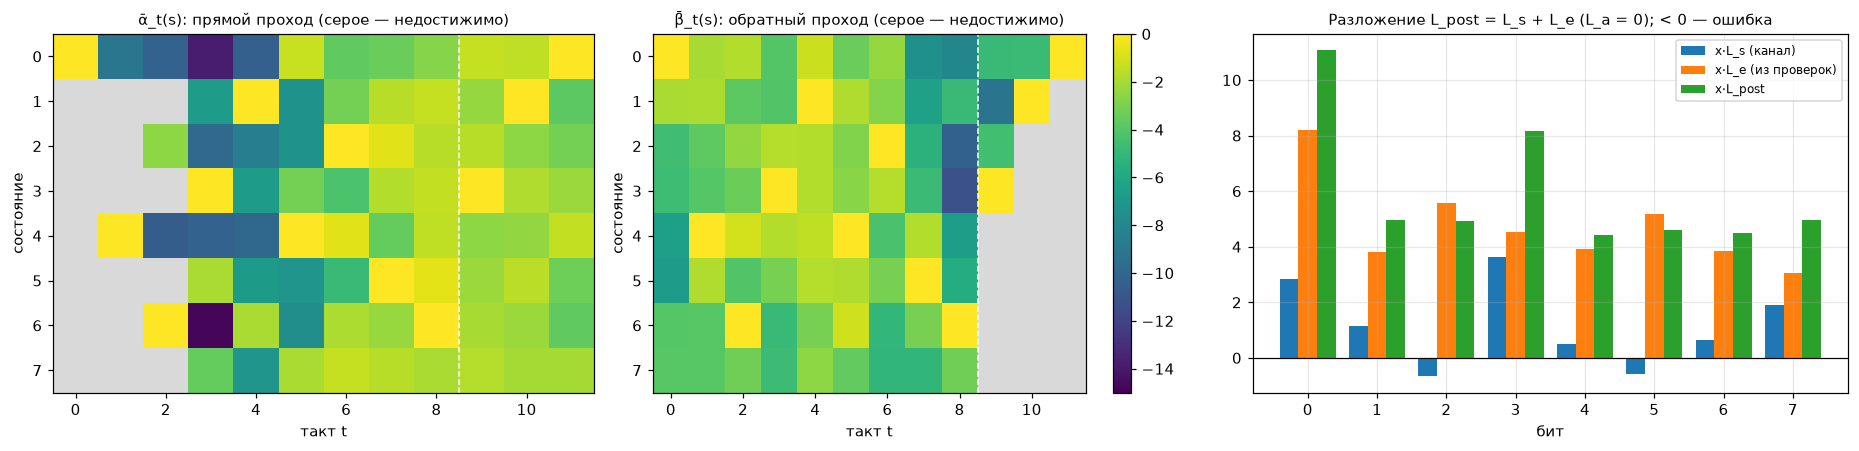

In [6]:
from scipy.special import logsumexp
K8 = 8
R8 = K8 / (2 * K8 + 6)
La8 = np.zeros(K8)
for seed8 in range(500):                          # ищем шум: в систематике есть ошибка, а BCJR её исправляет
    r8 = np.random.default_rng(seed8)
    u8 = r8.integers(0, 2, (1, K8)); z8, xt8, zt8 = rsc_encode(u8)
    Lc8 = channel(np.concatenate([u8, z8, xt8, zt8], 1), 1.0, R8, r8)[0]
    Ls8, Lp8, Lst8, Lpt8 = Lc8[:K8], Lc8[K8:2 * K8], Lc8[2 * K8:2 * K8 + 3], Lc8[2 * K8 + 3:]
    tr = {}
    Lpost8 = bcjr(Ls8[None], Lp8[None], La8[None], Lst8[None], Lpt8[None], True, trace=tr)[0]
    if ((Ls8 < 0) != u8[0]).any() and ((Lpost8 < 0) == u8[0]).all(): break
Lml8 = bcjr(Ls8[None], Lp8[None], La8[None], Lst8[None], Lpt8[None], False)[0]

allu = np.array([[(w >> i) & 1 for i in range(K8)] for w in range(2 ** K8)])
za, xta, zta = rsc_encode(allu)
met = 0.5 * ((1 - 2 * allu) @ (Ls8 + La8) + (1 - 2 * za) @ Lp8 + (1 - 2 * xta) @ Lst8 + (1 - 2 * zta) @ Lpt8)   # ln P(y|слово) + const
bf = np.array([logsumexp(met[allu[:, k] == 0]) - logsumexp(met[allu[:, k] == 1]) for k in range(K8)])
bfm = np.array([met[allu[:, k] == 0].max() - met[allu[:, k] == 1].max() for k in range(K8)])
x8 = 1 - 2 * u8[0]
print(" бит  u   L_s     BCJR   перебор | max-log  max перебора |  L_e = L_post − L_s")
for k in range(K8):
    print(f"  {k}   {u8[0, k]}  {Ls8[k]:+6.2f}  {Lpost8[k]:+6.2f}  {bf[k]:+6.2f}  | {Lml8[k]:+6.2f}   {bfm[k]:+6.2f}     |  {Lpost8[k] - Ls8[k]:+6.2f}")
print(f"ошибки канала в систематике: биты {np.nonzero((Ls8 < 0) != u8[0])[0]} — BCJR исправил их по проверкам и хвосту")
print(f"max |BCJR − перебор| = {np.abs(Lpost8 - bf).max():.1e}, max-log: {np.abs(Lml8 - bfm).max():.1e}  (max-log = лучший путь = Витерби)")

g0 = tr["g"][0, 0]
print(f"\nРазвёрнутый такт 0: из состояния 0 два ребра, L_s = {Ls8[0]:+.2f}, L_p = {Lp8[0]:+.2f}")
for b in (0, 1):
    print(f"  u={b} → s'={NXT[0, b]}, z={PAR[0, b]}: γ̄ = ½·({1 - 2 * b:+d})·L_s + ½·({1 - 2 * PAR[0, b]:+d})·L_p = {g0[0, b]:+.3f}")
print(f"  ᾱ₁ после нормировки: {np.round(np.where(tr['al'][1, 0] < -1e8, -np.inf, tr['al'][1, 0]), 3)}  (остальные состояния недостижимы)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for a, M, t in [(ax[0], tr["al"][:, 0].T, "ᾱ_t(s): прямой проход"), (ax[1], tr["be"][:, 0].T, "β̄_t(s): обратный проход")]:
    Mm = np.ma.masked_less(M, -1e8)
    im = a.imshow(np.maximum(Mm, -15), cmap="viridis", aspect="auto", vmin=-15, vmax=0); a.grid(False)
    a.set_facecolor("0.85"); a.set_xlabel("такт t"); a.set_ylabel("состояние"); a.set_title(t + " (серое — недостижимо)", fontsize=10)
    a.axvline(K8 + 0.5, color="w", ls="--", lw=1)
plt.colorbar(im, ax=ax[1])
kk = np.arange(K8)
ax[2].bar(kk - 0.27, x8 * Ls8, 0.27, label="x·L_s (канал)")
ax[2].bar(kk, x8 * (Lpost8 - Ls8), 0.27, label="x·L_e (из проверок)")
ax[2].bar(kk + 0.27, x8 * Lpost8, 0.27, label="x·L_post")
ax[2].axhline(0, color="k", lw=0.8); ax[2].set_xlabel("бит"); ax[2].legend(fontsize=8)
ax[2].set_title("Разложение L_post = L_s + L_e (L_a = 0); < 0 — ошибка", fontsize=10)
plt.tight_layout(); plt.show()

## 5. $\max^*$ и max-log-MAP
$$\max\nolimits^*(a,b)=\ln(e^a+e^b)=\max(a,b)+\ln\big(1+e^{-|a-b|}\big).$$
Поправка не больше $\ln2\approx0.69$ и быстро гаснет с $|a-b|$. **max-log-MAP** её выбрасывает: остаются сложения и сравнения (как в алгоритме Витерби), и не нужно знать $\sigma^2$ — масштаб LLR не влияет на решения. Цена — внешняя информация **завышена** по модулю: max-log учитывает лишь лучший путь, а не «толпу» конкурентов. Поэтому в турбодекодере внешние LLR max-log умножают на $\approx0.7$ (`SCALE_ML`) — как $\alpha$ в min-sum у LDPC.

Справа — оценка этого множителя по данным: внешние LLR log-MAP против max-log для одного BCJR на блоке $K$ = `K_TURBO` при `EBN0_DB`.

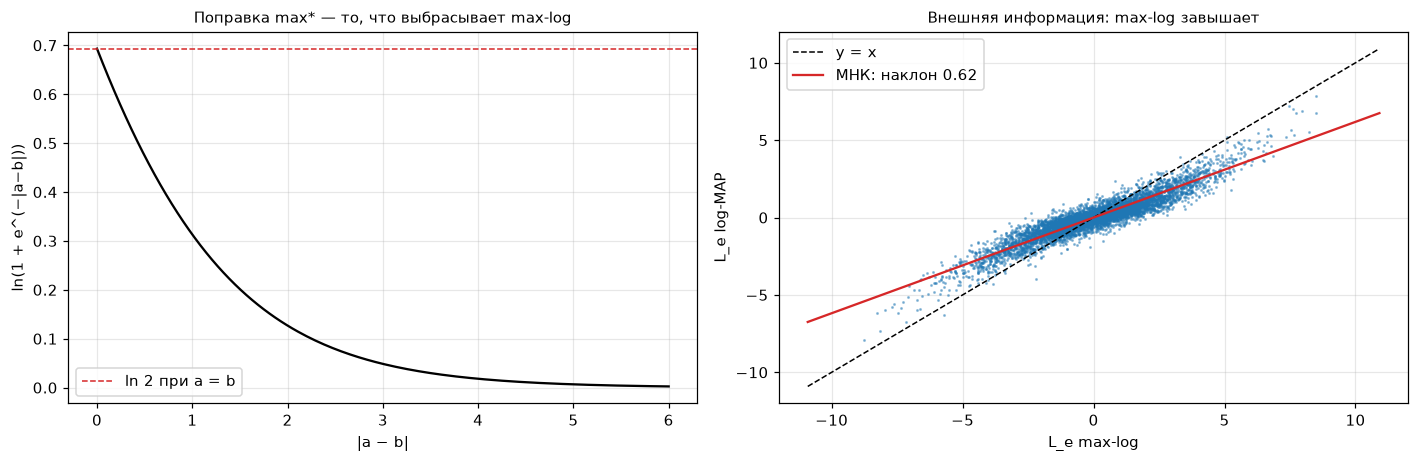

Совпадение знаков L_e: 87.63%; наклон 0.62 — отсюда SCALE_ML ≈ 0.7


In [7]:
dd = np.linspace(0, 6, 200)
r5 = np.random.default_rng(6)
u5 = r5.integers(0, 2, (20, K_TURBO)); c5 = turbo_encode(u5)
L5 = channel(c5, EBN0_DB, R3, r5); m5 = L5[:, :3 * K_TURBO].reshape(20, K_TURBO, 3)
args = (m5[..., 0], m5[..., 1], np.zeros((20, K_TURBO)), L5[:, 3 * K_TURBO:3 * K_TURBO + 3], L5[:, 3 * K_TURBO + 3:3 * K_TURBO + 6])
Le_ex = bcjr(*args, True) - m5[..., 0]; Le_ml = bcjr(*args, False) - m5[..., 0]
k_fit = np.sum(Le_ex * Le_ml) / np.sum(Le_ml ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(dd, np.log1p(np.exp(-dd)), "k"); ax[0].axhline(np.log(2), color="C3", ls="--", lw=1, label="ln 2 при a = b")
ax[0].set_xlabel("|a − b|"); ax[0].set_ylabel("ln(1 + e^(−|a−b|))"); ax[0].legend(); ax[0].set_title("Поправка max* — то, что выбрасывает max-log", fontsize=10)
sel = r5.choice(Le_ex.size, 6000, replace=False)
ax[1].plot(Le_ml.ravel()[sel], Le_ex.ravel()[sel], ".", ms=2, alpha=0.4)
lim = np.abs(Le_ml).max(); ll = np.array([-lim, lim])
ax[1].plot(ll, ll, "k--", lw=1, label="y = x"); ax[1].plot(ll, k_fit * ll, "C3", label=f"МНК: наклон {k_fit:.2f}")
ax[1].set_xlabel("L_e max-log"); ax[1].set_ylabel("L_e log-MAP"); ax[1].legend(); ax[1].set_title("Внешняя информация: max-log завышает", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Совпадение знаков L_e: {np.mean(np.sign(Le_ex) == np.sign(Le_ml)):.2%}; наклон {k_fit:.2f} — отсюда SCALE_ML ≈ 0.7")

## 6. Внешняя информация и «эхо»
Декодер 1 получил от декодера 2 априорную информацию $L_a$ и выдал $L_\text{post}=L_s+L_a+L_{e1}$. Если отдать соседу весь $L_\text{post}$, то:
- $L_a$ — это его же прошлое мнение: он получит его обратно и примет за **подтверждение**;
- $L_s$ сосед и так знает из канала — она будет засчитана дважды.

Положительная обратная связь: уверенность растёт, а ошибки замораживаются. Поэтому передаётся только $L_{e1}=L_\text{post}-L_s-L_a$ — то, что декодер узнал **из своих проверок** и чего у соседа нет. Связи между битами внутри одного свёрточного кода короткие, поэтому одна итерация даёт мало; перемежитель делает так, что внешняя информация от декодера 1 приходит к декодеру 2 от бит, далёких в его решётке, — почти независимой.

Эксперимент: $K$ = `K_TURBO`, `EBN0_DB`, без раннего останова; «эхо» передаёт $L_\text{post}-L_s$ (вычитается только канал).

внешняя (правильно)       : BER = 2.79e-03, FER = 0.03


эхо: соседу L_post − L_s  : BER = 7.43e-02, FER = 0.95


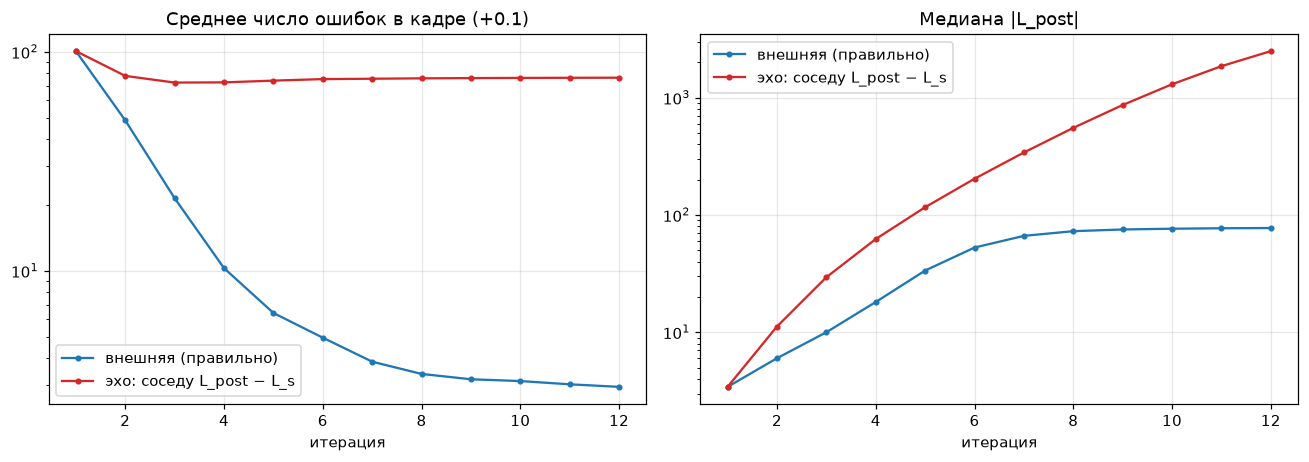

In [8]:
F6 = 200
u6 = rng.integers(0, 2, (F6, K_TURBO)); x6 = 1 - 2.0 * u6
L6 = channel(turbo_encode(u6), EBN0_DB, R3, rng)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for ext, col, name in [(True, "C0", "внешняя (правильно)"), (False, "C3", "эхо: соседу L_post − L_s")]:
    tr6 = []
    uh, _ = turbo_decode(L6, K_TURBO, 12, extrinsic=ext, early=False,
                         cb=lambda it, d: tr6.append(((d["L2"] * x6 < 0).sum(1).mean(), np.median(np.abs(d["L2"])))))
    tr6 = np.array(tr6); its = np.arange(1, len(tr6) + 1)
    ax[0].semilogy(its, tr6[:, 0] + 0.1, "o-", ms=3, color=col, label=name); ax[1].semilogy(its, tr6[:, 1], "o-", ms=3, color=col, label=name)
    print(f"{name:26s}: BER = {np.mean(uh != u6):.2e}, FER = {np.mean((uh != u6).any(1)):.2f}")
ax[0].set_title("Среднее число ошибок в кадре (+0.1)"); ax[1].set_title("Медиана |L_post|")
for a in ax: a.set_xlabel("итерация"); a.legend()
plt.tight_layout(); plt.show()

## 7. Турбо-итерации вручную: $K=40$
Самый короткий блок LTE. Подберём реализацию шума при $E_b/N_0=0$ дБ, где в систематических битах много ошибок, декодер 1 в одиночку их не исправляет, а после обмена — исправляет. Для каждой итерации видно:
- сколько ошибок после декодера 1 (свёрточный код + априори) и после декодера 2;
- как у ошибочных бит складывается $L_\text{post}=L_s+L_a+L_e$: канал говорит неверно, но внешняя информация обоих декодеров постепенно перевешивает.

Цвет — LLR, домноженный на передаваемый знак $x$ (синий — верно, красный — ошибка).

После сходимости LLR **перестают расти**: конкурирующий путь решётки, отличающийся в бите $t$, может «закрыться» хвостом, т.е. отличаться только символами, о которых есть лишь канальная информация (хвост и проверки), — их априори не усиливает. Внешняя информация ограничена, и итерации дальше ничего не меняют — поэтому и работает ранний останов.

seed = 19: ошибок в систематике канала 8 (биты [ 1  2 12 30 31 33 36 38])
  итерация 1: после декодера 1 —  7 ошибок, после декодера 2 —  7
  итерация 2: после декодера 1 —  3 ошибок, после декодера 2 —  2
  итерация 3: после декодера 1 —  0 ошибок, после декодера 2 —  0
  итерация 4: после декодера 1 —  0 ошибок, после декодера 2 —  0

Бит 1 (передан x = +1), всё домножено на x:
 итер |  L_s    L_a1    L_e1   L_post1 |  L_a2=L_e1  L_e2   L_post2
  1   |  -0.13   +0.00   +3.54    +3.41 |     +3.54    +0.60    +4.01
  2   |  -0.13   +0.60   +7.50    +7.97 |     +7.50    -0.39    +6.98
  3   |  -0.13   -0.39  +13.10   +12.58 |    +13.10    +7.30   +20.27
  4   |  -0.13   +7.30  +24.40   +31.56 |    +24.40    +7.95   +32.22
  проверка: L_post1 = L_s + L_a1 + L_e1 → True ; L_post2 = L_s + L_e1 + L_e2 → True


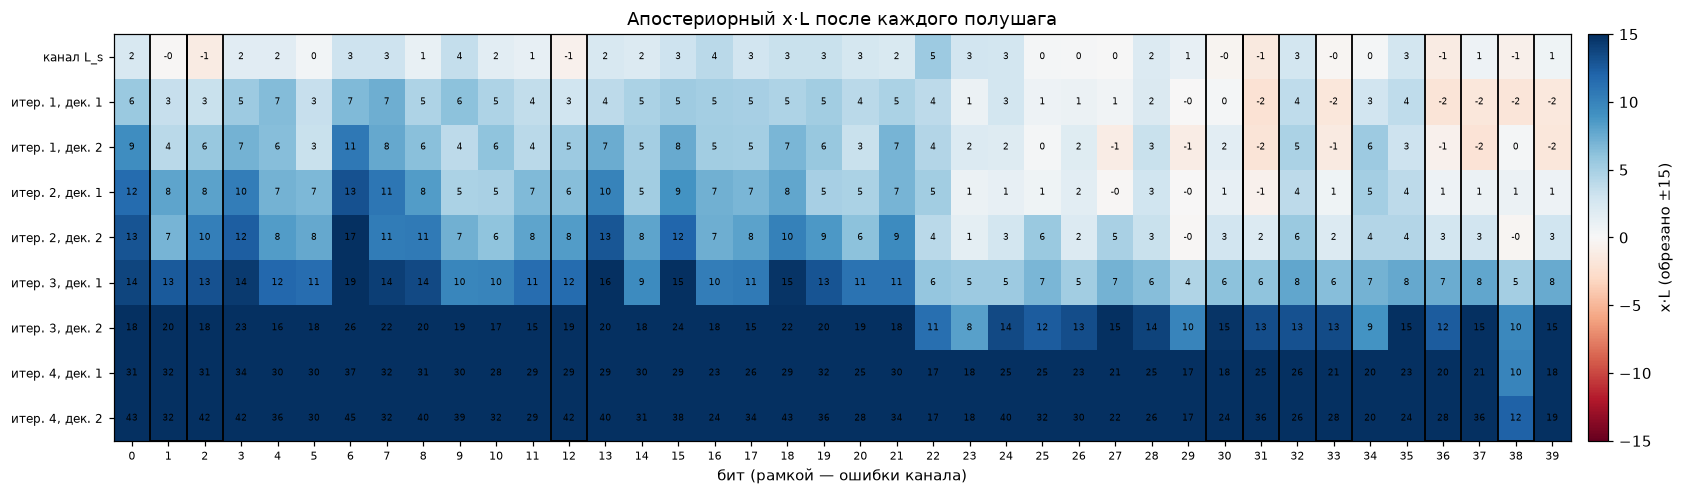

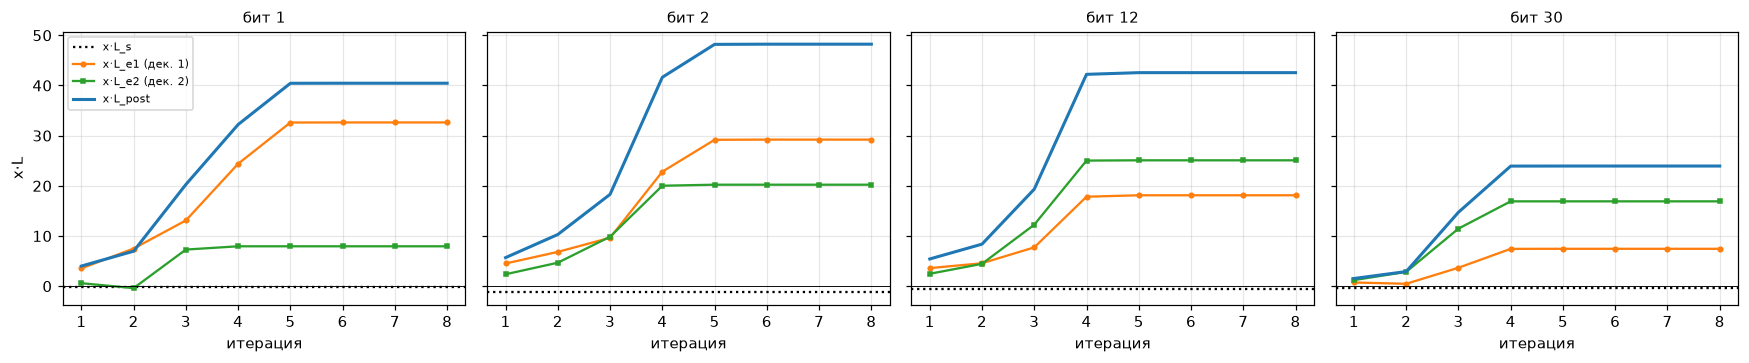

In [9]:
K7 = 40; R7 = K7 / (3 * K7 + 12)
for seed in range(3000):                          # канал: ≥4 ошибки в систематике; декодеру нужно ≥3 итерации
    rs = np.random.default_rng(seed)
    u7 = rs.integers(0, 2, (1, K7)); L7 = channel(turbo_encode(u7), 0.0, R7, rs)
    rec = []
    uh7, _ = turbo_decode(L7, K7, ITERS, early=False, cb=lambda it, d: rec.append({k: v[0].copy() for k, v in d.items()}))
    e1 = [((r["L1"] < 0) != u7[0]).sum() for r in rec]; e2 = [((r["L2"] < 0) != u7[0]).sum() for r in rec]
    if (uh7 == u7).all() and ((L7[0, 0:3 * K7:3] < 0) != u7[0]).sum() >= 4 and e2[0] > 0 and e2[1] > 0 and e2[2] == 0:
        break
x7 = 1 - 2.0 * u7[0]; Ls7 = L7[0, 0:3 * K7:3]
err7 = np.nonzero((Ls7 < 0) != u7[0])[0]
print(f"seed = {seed}: ошибок в систематике канала {len(err7)} (биты {err7})")
for it in range(4):
    print(f"  итерация {it + 1}: после декодера 1 — {e1[it]:2d} ошибок, после декодера 2 — {e2[it]:2d}")
b = err7[0]
print(f"\nБит {b} (передан x = {x7[b]:+.0f}), всё домножено на x:")
print(" итер |  L_s    L_a1    L_e1   L_post1 |  L_a2=L_e1  L_e2   L_post2")
for it in range(4):
    r = rec[it]
    print(f"  {it + 1}   | {x7[b] * Ls7[b]:+6.2f} {x7[b] * r['La1'][b]:+7.2f} {x7[b] * r['Le1'][b]:+7.2f} {x7[b] * r['L1'][b]:+8.2f} |"
          f"   {x7[b] * r['Le1'][b]:+7.2f}  {x7[b] * r['Le2'][b]:+7.2f} {x7[b] * r['L2'][b]:+8.2f}")
print("  проверка: L_post1 = L_s + L_a1 + L_e1 →", np.allclose(rec[0]["L1"], Ls7 + rec[0]["La1"] + rec[0]["Le1"]),
      "; L_post2 = L_s + L_e1 + L_e2 →", np.allclose(rec[0]["L2"], Ls7 + rec[0]["Le1"] + rec[0]["Le2"]))

rows = [x7 * Ls7] + sum([[x7 * rec[it]["L1"], x7 * rec[it]["L2"]] for it in range(4)], [])
labels = ["канал L_s"] + sum([[f"итер. {it + 1}, дек. 1", f"итер. {it + 1}, дек. 2"] for it in range(4)], [])
M7 = np.array(rows)
fig, a = plt.subplots(figsize=(17, 4.6))
im = a.imshow(np.clip(M7, -15, 15), cmap="RdBu", vmin=-15, vmax=15, aspect="auto"); a.grid(False)
for (i, j), v in np.ndenumerate(M7): a.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6)
a.set_yticks(range(len(labels))); a.set_yticklabels(labels, fontsize=8); a.set_xticks(range(K7)); a.set_xticklabels(range(K7), fontsize=7)
for j in err7: a.add_patch(plt.Rectangle((j - 0.5, -0.5), 1, len(labels), fill=False, ec="k", lw=1.2))
a.set_xlabel("бит (рамкой — ошибки канала)"); plt.colorbar(im, ax=a, label="x·L (обрезано ±15)", pad=0.01)
a.set_title("Апостериорный x·L после каждого полушага")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, min(4, len(err7)), figsize=(16, 3.4), sharey=True)
hs = np.arange(1, ITERS + 1)
for a, b in zip(np.atleast_1d(ax), err7[:4]):
    a.axhline(x7[b] * Ls7[b], color="k", ls=":", label="x·L_s")
    a.plot(hs, [x7[b] * r["Le1"][b] for r in rec], "C1o-", ms=3, label="x·L_e1 (дек. 1)")
    a.plot(hs, [x7[b] * r["Le2"][b] for r in rec], "C2s-", ms=3, label="x·L_e2 (дек. 2)")
    a.plot(hs, [x7[b] * r["L2"][b] for r in rec], "C0-", lw=2, label="x·L_post")
    a.axhline(0, color="k", lw=0.6); a.set_title(f"бит {b}", fontsize=10); a.set_xlabel("итерация")
np.atleast_1d(ax)[0].legend(fontsize=7); np.atleast_1d(ax)[0].set_ylabel("x·L")
plt.tight_layout(); plt.show()

# Часть II. $K = 1024$ в деле

## 8. Итерации изнутри
100 кадров при `EBN0_DB`, все `ITERS` итераций без раннего останова. Слева — ошибки в каждом кадре после каждого полушага (декодер 1, декодер 2, …). Как и у LDPC, сходимость лавинообразная: пока внешняя информация слабая, полушаги дают мало, затем ошибки исчезают за 1–2 итерации. Красные — кадры, которые не сошлись. Справа — распределение апостериорного $x\cdot L$: масса уходит вправо, уверенность растёт на порядки.

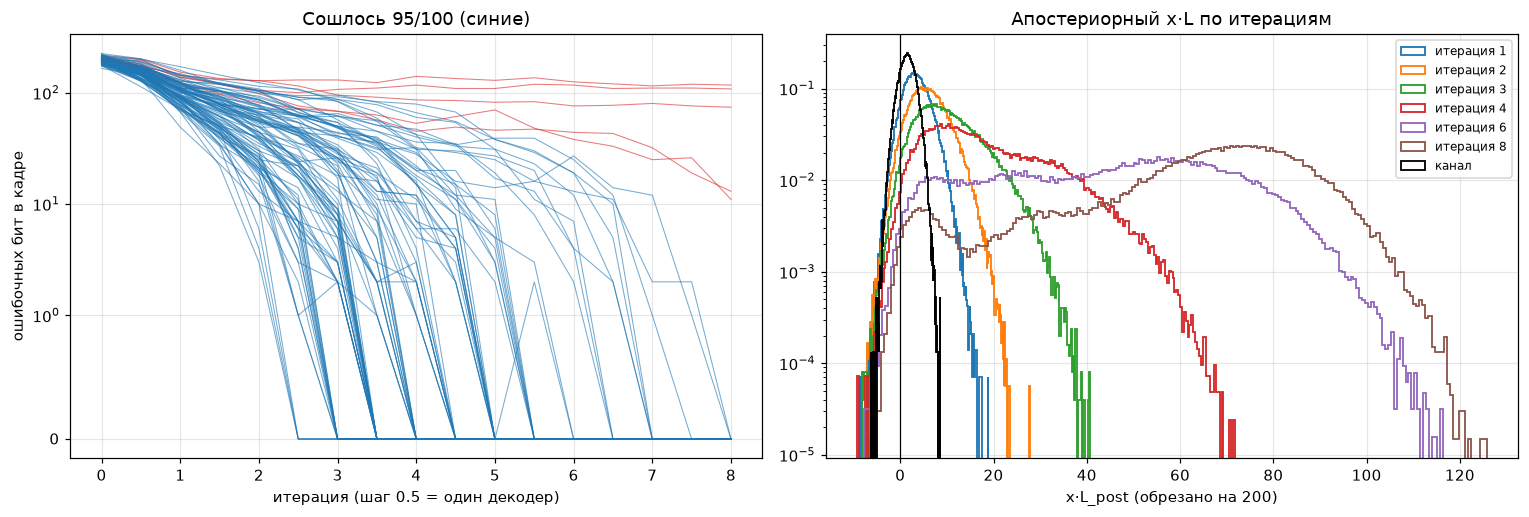

Ошибок в систематике канала: 197 из 1024 (19.3%); после декодера: BER = 3.2e-03, FER = 0.05


In [10]:
F8 = 100
u8b = rng.integers(0, 2, (F8, K_TURBO)); x8b = 1 - 2.0 * u8b
L8b = channel(turbo_encode(u8b), EBN0_DB, R3, rng)
hist8 = []
def rec8(it, d):
    hist8.append(dict(e1=(d["L1"] * x8b < 0).sum(1), e2=(d["L2"] * x8b < 0).sum(1), xL=(d["L2"] * x8b).astype(np.float32),
                      IA=mi(d["La1"], x8b), IE1=mi(d["Le1"], x8b), IE2=mi(d["Le2"], x8b)))
uh8, _ = turbo_decode(L8b, K_TURBO, ITERS, early=False, cb=rec8)
E8 = np.array([(L8b[:, 0:3 * K_TURBO:3] * x8b < 0).sum(1)] + sum([[h["e1"], h["e2"]] for h in hist8], []))
conv8 = (uh8 == u8b).all(1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
hx = np.arange(E8.shape[0]) / 2
for f in range(F8):
    ax[0].plot(hx, E8[:, f], color="C0" if conv8[f] else "C3", lw=0.7, alpha=0.6)
ax[0].set_yscale("symlog", linthresh=1); ax[0].set_xlabel("итерация (шаг 0.5 = один декодер)"); ax[0].set_ylabel("ошибочных бит в кадре")
ax[0].set_title(f"Сошлось {conv8.sum()}/{F8} (синие)")
for it in [0, 1, 2, 3, 5, ITERS - 1]:
    if it < len(hist8):
        ax[1].hist(np.clip(hist8[it]["xL"].ravel(), -30, 200), 200, density=True, histtype="step", lw=1.2, label=f"итерация {it + 1}")
ax[1].hist(np.clip((L8b[:, 0:3 * K_TURBO:3] * x8b).ravel(), -30, 200), 200, density=True, histtype="step", lw=1.2, color="k", label="канал")
ax[1].set_yscale("log"); ax[1].axvline(0, color="k", lw=0.8); ax[1].legend(fontsize=8); ax[1].set_xlabel("x·L_post (обрезано на 200)")
ax[1].set_title("Апостериорный x·L по итерациям")
plt.tight_layout(); plt.show()
print(f"Ошибок в систематике канала: {E8[0].mean():.0f} из {K_TURBO} ({E8[0].mean() / K_TURBO:.1%}); после декодера: BER = {np.mean(uh8 != u8b):.1e}, FER = {1 - conv8.mean():.2f}")

## 9. EXIT-диаграмма и порог
Опишем априорный вход декодера одним числом — взаимной информацией $I_A$ с битом, — считая его гауссовым LLR $\mathcal N(x\sigma_A^2/2,\sigma_A^2)$, $I_A=J(\sigma_A)$ (как в EXIT для LDPC). Подадим такой $L_a$ в один BCJR вместе с каналом и измерим информацию внешнего выхода $I_E=I(L_e;x)$. Получим **передаточную характеристику** $I_E=T(I_A)$ — её снимают Монте-Карло, формулы нет: свёрточный код слишком сложен.

Оба кодера одинаковы, поэтому вторая кривая — та же $T$, отражённая относительно диагонали. Декодер ходит «лесенкой»: $I_{A1}\to I_{E1}=I_{A2}\to I_{E2}=I_{A1}\to\dots$ Пока между кривыми есть **туннель** ($T(I)>I$ для всех $I<1$), лесенка доходит до $I=1$. **Порог** — $E_b/N_0$, при котором туннель открывается. В отличие от LDPC, $T(0)>0$: даже без априори свёрточный код что-то извлекает из своих проверок.

Слева — ниже порога, справа — `EBN0_DB` и **измеренная** траектория из раздела 8.

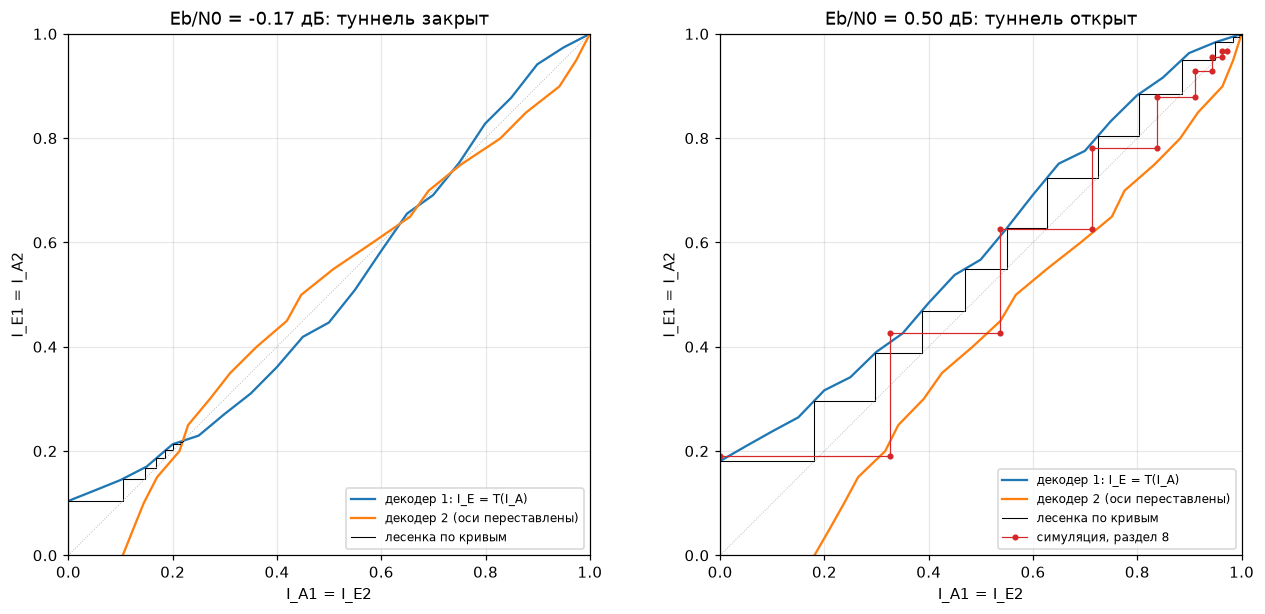

Порог по EXIT: 0.13 дБ; Шеннон для BPSK при R = 1/3: -0.50 дБ → разрыв 0.6 дБ
Минимальный зазор T(I) − I по Eb/N0: -0.4: -0.092  -0.3: -0.075  -0.2: -0.058  -0.1: -0.040  -0.0: -0.023  +0.1: -0.005  +0.2: +0.013  +0.3: +0.031  +0.4: +0.033  +0.5: +0.035  +0.6: +0.036


In [11]:
def exit_curve(e, IA, K=K_TURBO, B=20, seed=0):
    r_ = np.random.default_rng(seed)
    u_ = r_.integers(0, 2, (B, K)); L_ = channel(turbo_encode(u_), e, R3, r_)
    m_ = L_[:, :3 * K].reshape(B, K, 3); x_ = 1 - 2.0 * u_
    out = []
    for I in IA:
        sA = Jinv(I); La_ = sA ** 2 / 2 * x_ + sA * r_.standard_normal(x_.shape)     # гауссово априори с информацией I
        L1_ = bcjr(m_[..., 0], m_[..., 1], La_, L_[:, 3 * K:3 * K + 3], L_[:, 3 * K + 3:3 * K + 6])
        out.append(mi(L1_ - m_[..., 0] - La_, x_))
    return np.array(out)

IA = np.linspace(0, 0.999, 21)
eg = np.arange(-0.4, 0.61, 0.1)
gaps = np.array([(exit_curve(e, IA) - IA)[:-1].min() for e in eg])
TH_T = float(np.interp(0, gaps, eg))

def stairs(T_, start=0.0, n=60):
    xs, ys, I = [start], [0.0], start
    for _ in range(n):
        Ie = float(np.interp(I, IA, T_)); xs += [I, Ie]; ys += [Ie, Ie]; I = Ie
        if I > 0.999: break
    return xs, ys

fig, ax = plt.subplots(1, 2, figsize=(12, 5.6))
for a, e in zip(ax, [TH_T - 0.3, EBN0_DB]):
    T_ = exit_curve(e, IA)
    a.plot(IA, T_, "C0", lw=1.5, label="декодер 1: I_E = T(I_A)")
    a.plot(T_, IA, "C1", lw=1.5, label="декодер 2 (оси переставлены)")
    a.plot(*stairs(T_), "k", lw=0.7, label="лесенка по кривым")
    a.plot([0, 1], [0, 1], color="0.7", lw=0.6, ls=":")
    a.set_title(f"Eb/N0 = {e:.2f} дБ: туннель {'открыт' if (T_ - IA)[:-1].min() > 0 else 'закрыт'}")
    a.set_xlabel("I_A1 = I_E2"); a.set_ylabel("I_E1 = I_A2"); a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect("equal")
xs, ys = [], []
for h in hist8:
    xs += [h["IA"], h["IE2"]]; ys += [h["IE1"], h["IE1"]]
ax[1].plot(xs, ys, "C3o-", ms=3, lw=0.8, label=f"симуляция, раздел 8")
for a in ax: a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
print(f"Порог по EXIT: {TH_T:.2f} дБ; Шеннон для BPSK при R = 1/3: {biawgn_limit(1 / 3):.2f} дБ → разрыв {TH_T - biawgn_limit(1 / 3):.1f} дБ")
print("Минимальный зазор T(I) − I по Eb/N0:", "  ".join(f"{e:+.1f}: {g:+.3f}" for e, g in zip(eg, gaps)))

## 10. Водопад: BER/FER против $E_b/N_0$
Три декодера: log-MAP (точный $\max^*$), max-log-MAP без масштаба и с масштабом `SCALE_ML`. Для сравнения — **один** RSC (систематика + одна проверка, $R\approx1/2$), декодированный одним BCJR: это «просто свёрточный код» с той же решёткой. Пунктир — предел Шеннона при $R=1/3$ и EXIT-порог: на конечной длине водопад правее порога.

Ранний останов: кадр замораживается, как только жёсткие решения обоих декодеров совпали (в железе обычно проверяют CRC блока). Справа — BER после каждой итерации log-MAP.

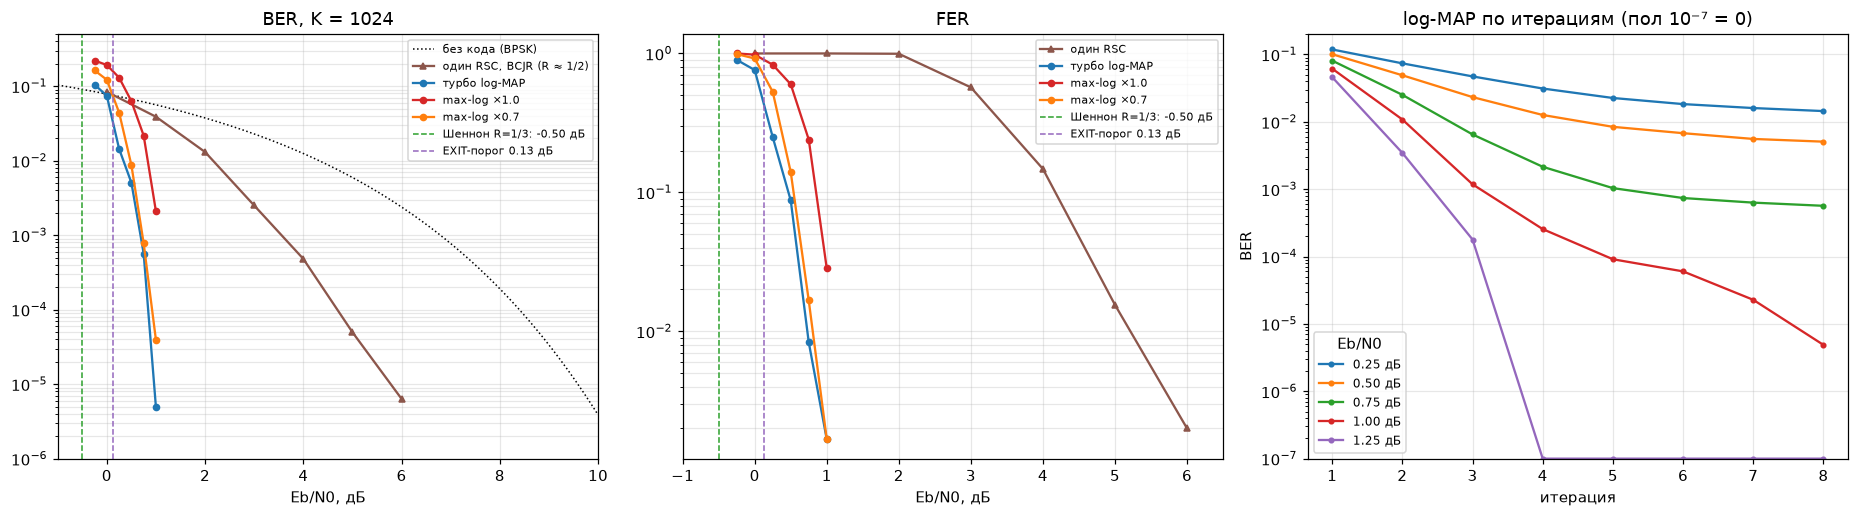

 Eb/N0 |  log-MAP: BER    FER | max-log×1: BER   FER | max-log×0.7: BER  FER  итер* | кадров
 -0.25 |   1.1e-01  0.900 |   2.2e-01  1.000 |   1.6e-01  0.990   8.0 | 100
  0.00 |   7.5e-02  0.760 |   1.9e-01  0.980 |   1.2e-01  0.920   7.9 | 100
  0.25 |   1.4e-02  0.250 |   1.3e-01  0.830 |   4.4e-02  0.530   7.0 | 200
  0.50 |   5.1e-03  0.087 |   6.3e-02  0.600 |   8.8e-03  0.140   5.9 | 400
  0.75 |   5.7e-04  0.008 |   2.2e-02  0.240 |   7.8e-04  0.017   4.4 | 600
  1.00 |   4.9e-06  0.002 |   2.1e-03  0.028 |   3.9e-05  0.002   3.6 | 600
  1.25 |   0.0e+00  0.000 |   0.0e+00  0.000 |   0.0e+00  0.000   3.2 | 600
* среднее число итераций с ранним остановом (log-MAP здесь шёл без останова, чтобы снять BER по итерациям)
один RSC: 0 дБ → BER 8.4e-02, 1 дБ → BER 3.9e-02, 2 дБ → BER 1.3e-02, 3 дБ → BER 2.5e-03, 4 дБ → BER 4.8e-04, 5 дБ → BER 5.0e-05, 6 дБ → BER 6.3e-06

BER = 1e-4: без кода 8.4 дБ, один RSC 4.7 дБ, турбо 0.84 дБ → выигрыш 7.6 дБ, из них 3.9 дБ даёт итеративный обмен меж

In [12]:
def sim_turbo(ebn0_list, K=K_TURBO, exact=True, scale=SCALE_ML, pi=None, mask=None, min_fe=30, max_frames=600, batch=100, track=False):
    res, per_it = [], []
    for e in ebn0_list:
        be = fe = nf = its = 0; pit = np.zeros(ITERS)
        while fe < min_fe and nf < max_frames:
            u_ = rng.integers(0, 2, (batch, K)); c_ = turbo_encode(u_, pi)
            R_ = K / (c_.shape[1] if mask is None else mask.sum())
            L_ = channel(c_, e, R_, rng, mask)
            def cb(it, d): pit[it] += np.sum((d["L2"] < 0) != u_)
            uh, nit = turbo_decode(L_, K, ITERS, exact, scale, cb=cb if track else None, pi=pi, early=not track)   # для BER по итерациям — без останова
            err = uh != u_; be += err.sum(); fe += err.any(1).sum(); nf += batch; its += nit.sum()
        res.append((be / (nf * K), fe / nf, its / nf, nf)); per_it.append(pit / (nf * K))
    return np.array(res), np.array(per_it)

def sim_rsc(ebn0_list, K=K_TURBO, min_fe=30, max_frames=2000, batch=200):
    res = []
    for e in ebn0_list:
        be = fe = nf = 0
        while fe < min_fe and nf < max_frames:
            u_ = rng.integers(0, 2, (batch, K)); z_, xt_, zt_ = rsc_encode(u_)
            c_ = np.concatenate([u_, z_, xt_, zt_], 1)
            L_ = channel(c_, e, K / c_.shape[1], rng)
            uh = (bcjr(L_[:, :K], L_[:, K:2 * K], np.zeros((batch, K)), L_[:, 2 * K:2 * K + 3], L_[:, 2 * K + 3:]) < 0)
            err = uh != u_; be += err.sum(); fe += err.any(1).sum(); nf += batch
        res.append((be / (nf * K), fe / nf, nf))
    return np.array(res)

eb10 = np.arange(-0.25, 1.26, 0.25)
r_log, it_log = sim_turbo(eb10, track=True)
r_ml1, _ = sim_turbo(eb10, exact=False, scale=1.0)
r_ml7, _ = sim_turbo(eb10, exact=False, scale=SCALE_ML)
eb_rsc = np.arange(0.0, 6.1, 1.0)
r_rsc = sim_rsc(eb_rsc)
SH3 = biawgn_limit(1 / 3)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
eg = np.linspace(-1, 10, 200)
ax[0].semilogy(eg, 0.5 * erfc(np.sqrt(10 ** (eg / 10))), "k:", lw=1, label="без кода (BPSK)")
ok = r_rsc[:, 0] > 0
ax[0].semilogy(eb_rsc[ok], r_rsc[ok, 0], "^-", color="C5", ms=4, label="один RSC, BCJR (R ≈ 1/2)")
ax[1].semilogy(eb_rsc[r_rsc[:, 1] > 0], r_rsc[r_rsc[:, 1] > 0, 1], "^-", color="C5", ms=4, label="один RSC")
for r_, lab, c_ in [(r_log, "турбо log-MAP", "C0"), (r_ml1, "max-log ×1.0", "C3"), (r_ml7, f"max-log ×{SCALE_ML}", "C1")]:
    ok = r_[:, 0] > 0
    ax[0].semilogy(eb10[ok], r_[ok, 0], "o-", color=c_, ms=4, label=lab)
    ax[1].semilogy(eb10[r_[:, 1] > 0], r_[r_[:, 1] > 0, 1], "o-", color=c_, ms=4, label=lab)
for a in ax[:2]:
    a.axvline(SH3, color="C2", ls="--", lw=1, label=f"Шеннон R=1/3: {SH3:.2f} дБ"); a.axvline(TH_T, color="C4", ls="--", lw=1, label=f"EXIT-порог {TH_T:.2f} дБ")
    a.set_xlabel("Eb/N0, дБ"); a.legend(fontsize=7); a.grid(which="both", alpha=0.3)
ax[0].set_xlim(-1, 10); ax[0].set_ylim(1e-6, 0.5); ax[0].set_title(f"BER, K = {K_TURBO}"); ax[1].set_xlim(-1, 6.5); ax[1].set_title("FER")
for j, e in enumerate(eb10):
    if it_log[j, 0] > 0 and r_log[j, 0] < 0.05:
        ax[2].semilogy(np.arange(1, ITERS + 1), np.maximum(it_log[j], 1e-7), "o-", ms=3, label=f"{e:.2f} дБ")
ax[2].set_xlabel("итерация"); ax[2].set_ylabel("BER"); ax[2].set_ylim(1e-7, 0.2); ax[2].legend(title="Eb/N0", fontsize=8); ax[2].set_title("log-MAP по итерациям (пол 10⁻⁷ = 0)")
plt.tight_layout(); plt.show()

print(" Eb/N0 |  log-MAP: BER    FER | max-log×1: BER   FER | max-log×0.7: BER  FER  итер* | кадров")
for j, e in enumerate(eb10):
    a_, b_, c_ = r_log[j], r_ml1[j], r_ml7[j]
    print(f" {e:5.2f} |  {a_[0]:8.1e} {a_[1]:6.3f} |  {b_[0]:8.1e} {b_[1]:6.3f} |  {c_[0]:8.1e} {c_[1]:6.3f}  {c_[2]:4.1f} | {int(a_[3])}")
print("* среднее число итераций с ранним остановом (log-MAP здесь шёл без останова, чтобы снять BER по итерациям)")
print("один RSC: " + ", ".join(f"{e:.0f} дБ → BER {r[0]:.1e}" for e, r in zip(eb_rsc, r_rsc)))
target = 1e-4
e_unc = brentq(lambda e: 0.5 * erfc(np.sqrt(10 ** (e / 10))) - target, 0, 15)
def cross(eb, ber):
    i = np.argmax((ber < target) & (ber > 0))
    return np.interp(np.log10(target), np.log10(ber[[i, i - 1]]), eb[[i, i - 1]]) if i > 0 else np.nan
e_t, e_r = cross(eb10, r_log[:, 0]), cross(eb_rsc, r_rsc[:, 0])
print(f"\nBER = 1e-4: без кода {e_unc:.1f} дБ, один RSC {e_r:.1f} дБ, турбо {e_t:.2f} дБ → выигрыш {e_unc - e_t:.1f} дБ, "
      f"из них {e_r - e_t:.1f} дБ даёт итеративный обмен между двумя кодами")

## 11. Перемежитель решает всё
Тот же декодер, три перемежителя ($K$ = `K_TURBO`, log-MAP). **Без перемежителя** оба кодера видят одинаковый вход: второй декодер повторяет первый, его «внешняя» информация — то же знание, и обмен вырождается в «эхо» из раздела 6. Код не лучше одного RSC: FER ≈ 1 во всём диапазоне. **Случайный** перемежитель хорош в водопаде, но случайно сводит некоторые пары бит вместе — несколько слов малого веса, пол ниже. **QPP** — водопад того же уровня, разнос гарантирован алгебраически, и он ещё параллелится без конфликтов памяти.

На $K\approx1000$ пол виден лишь при FER $\sim10^{-4}$ и ниже, на что здесь не хватит кадров; разница «случайный vs QPP» на графике в пределах статистики (у случайного 19 слов веса < 30, у QPP одно — раздел 3), а «без перемежителя» — разгромная.

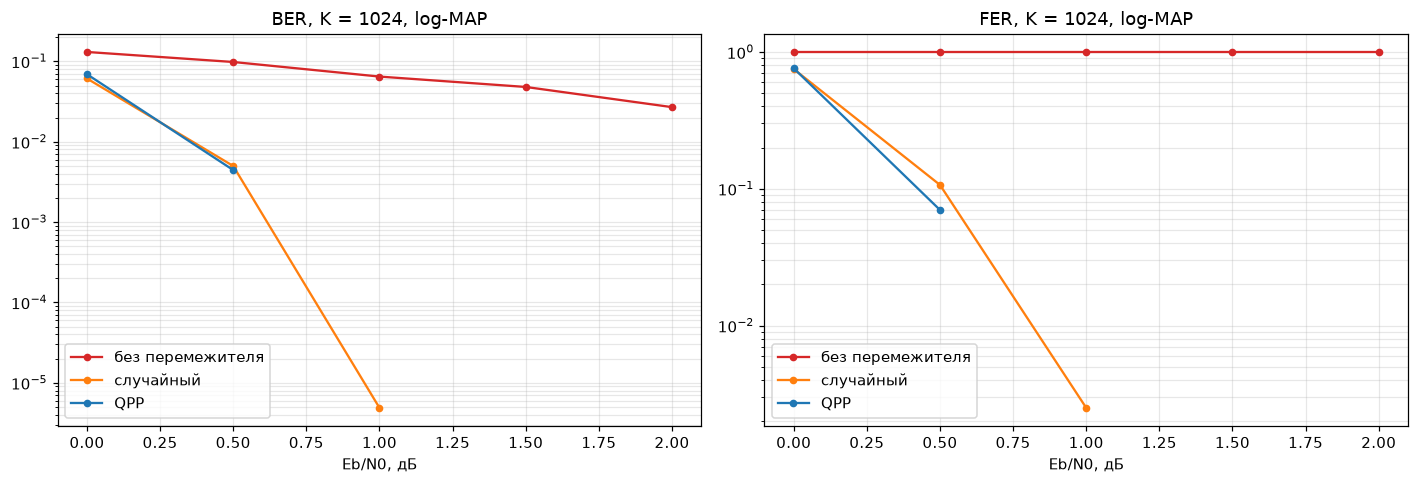

без перемежителя : 0.0 дБ: FER 1.000  0.5 дБ: FER 1.000  1.0 дБ: FER 1.000  1.5 дБ: FER 1.000  2.0 дБ: FER 1.000
случайный        : 0.0 дБ: FER 0.750  0.5 дБ: FER 0.107  1.0 дБ: FER 0.003  1.5 дБ: FER 0.000  2.0 дБ: FER 0.000
QPP              : 0.0 дБ: FER 0.760  0.5 дБ: FER 0.070  1.0 дБ: FER 0.000  1.5 дБ: FER 0.000  2.0 дБ: FER 0.000


In [13]:
eb11 = np.arange(0.0, 2.01, 0.5)
res11 = {name: sim_turbo(eb11, pi=p, max_frames=400)[0] for name, p in pis.items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, r_), c_ in zip(res11.items(), ["C3", "C1", "C0"]):
    for a, k in zip(ax, (0, 1)):
        ok = r_[:, k] > 0
        a.semilogy(eb11[ok], r_[ok, k], "o-", color=c_, ms=4, label=name)
for a, t in zip(ax, ("BER", "FER")):
    a.set_xlabel("Eb/N0, дБ"); a.set_title(f"{t}, K = {K_TURBO}, log-MAP"); a.legend(); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()
for name, r_ in res11.items():
    print(f"{name:17s}: " + "  ".join(f"{e:.1f} дБ: FER {r[1]:.3f}" for e, r in zip(eb11, r_)))

## 12. Длина блока
Чем длиннее блок, тем больше «простора» у перемежителя и тем ближе к асимптоте (EXIT-порог): водопад становится круче и сдвигается влево. На $K=40$ водопада почти нет — кривая пологая, как у обычного свёрточного кода: перемежитель на 40 бит не может далеко разнести биты, и внешняя информация сильно коррелирована. LTE использует 188 размеров от 40 до 6144; длинные транспортные блоки режутся на сегменты по 6144.

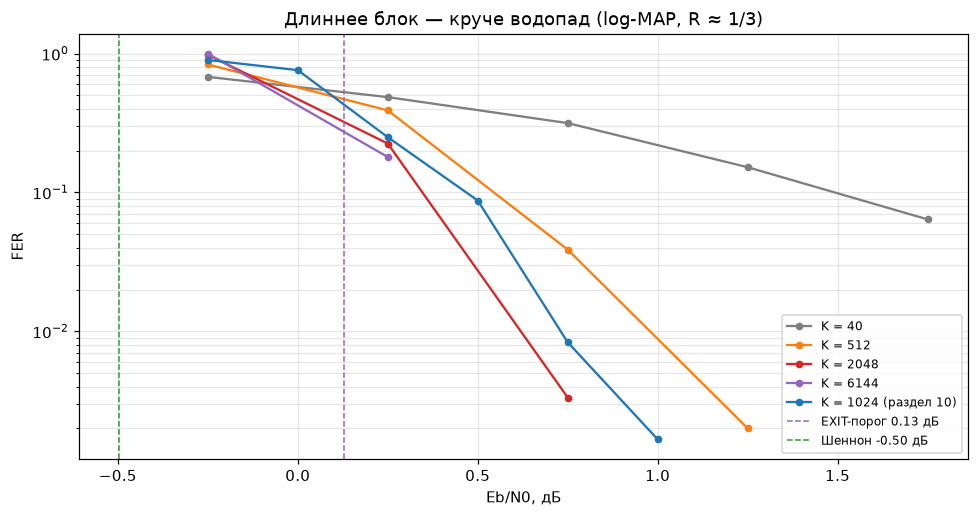

FER: Eb/N0       K=40     K=512    K=2048    K=6144
     -0.25   6.80e-01  8.35e-01  9.80e-01  1.00e+00
      0.25   4.86e-01  3.90e-01  2.25e-01  1.80e-01
      0.75   3.16e-01  3.87e-02  3.33e-03  0.00e+00
      1.25   1.52e-01  2.00e-03  0.00e+00  0.00e+00
      1.75   6.40e-02  0.00e+00  0.00e+00  0.00e+00


In [14]:
lens = [40, 512, 2048, 6144]
eb12 = np.arange(-0.25, 2.01, 0.5)
mf = {40: 4000, 512: 1000, 2048: 300, 6144: 100}
bt = {40: 500, 512: 200, 2048: 100, 6144: 50}
res12 = {K_: sim_turbo(eb12, K=K_, max_frames=mf[K_], batch=bt[K_])[0] for K_ in lens}
fig, a = plt.subplots(figsize=(9, 4.8))
for K_, c_ in zip(lens, ["C7", "C1", "C3", "C4"]):
    r_ = res12[K_]; ok = r_[:, 1] > 0
    a.semilogy(eb12[ok], r_[ok, 1], "o-", color=c_, ms=4, label=f"K = {K_}")
ok = r_log[:, 1] > 0
a.semilogy(eb10[ok], r_log[ok, 1], "o-", color="C0", ms=4, label=f"K = {K_TURBO} (раздел 10)")
a.axvline(TH_T, color="C4", ls="--", lw=1, label=f"EXIT-порог {TH_T:.2f} дБ"); a.axvline(SH3, color="C2", ls="--", lw=1, label=f"Шеннон {SH3:.2f} дБ")
a.set_xlabel("Eb/N0, дБ"); a.set_ylabel("FER"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3); a.set_title("Длиннее блок — круче водопад (log-MAP, R ≈ 1/3)")
plt.tight_layout(); plt.show()
print("FER: Eb/N0 " + "".join(f"{f'K={K_}':>10s}" for K_ in lens))
for j, e in enumerate(eb12): print(f"     {e:5.2f} " + "".join(f"{res12[K_][j, 1]:10.2e}" for K_ in lens))

## 13. Турбо против LDPC при одинаковых $R$ и $n$
Для честного сравнения с регулярным LDPC (3,6) из соседнего ноутбука ($R\approx1/2$, $n=1008$, sum-product, 50 итераций) берём $K=512$ и **выкалываем** проверочные биты через один (у декодера на их месте LLR = 0): $n=1036$, $R\approx0.494$. В LTE то же делает rate matching через кольцевой буфер.

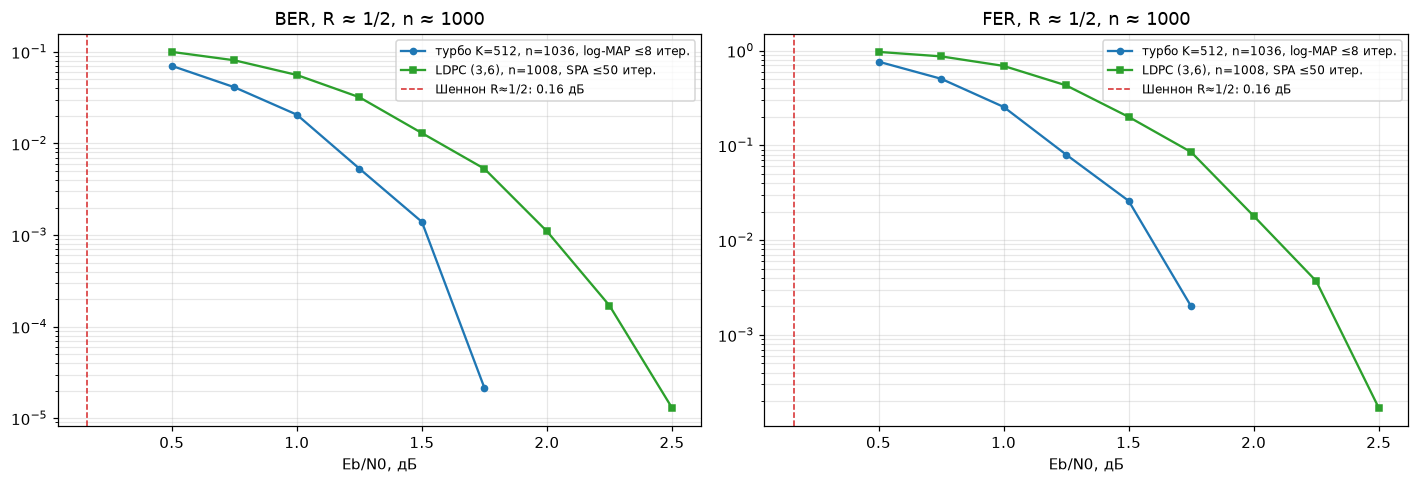

Eb/N0 0.50 дБ: турбо BER 7.0e-02 FER 0.765 (200 кадров) | LDPC (3,6) BER 1.0e-01 FER 9.7e-01
Eb/N0 0.75 дБ: турбо BER 4.1e-02 FER 0.505 (200 кадров) | LDPC (3,6) BER 8.1e-02 FER 8.7e-01
Eb/N0 1.00 дБ: турбо BER 2.1e-02 FER 0.255 (200 кадров) | LDPC (3,6) BER 5.6e-02 FER 6.9e-01
Eb/N0 1.25 дБ: турбо BER 5.3e-03 FER 0.080 (400 кадров) | LDPC (3,6) BER 3.2e-02 FER 4.3e-01
Eb/N0 1.50 дБ: турбо BER 1.4e-03 FER 0.026 (1000 кадров) | LDPC (3,6) BER 1.3e-02 FER 2.0e-01
Eb/N0 1.75 дБ: турбо BER 2.1e-05 FER 0.002 (1000 кадров) | LDPC (3,6) BER 5.3e-03 FER 8.5e-02
Eb/N0 2.00 дБ: турбо BER 0.0e+00 FER 0.000 (1000 кадров) | LDPC (3,6) BER 1.1e-03 FER 1.8e-02
Eb/N0 2.25 дБ: турбо BER 0.0e+00 FER 0.000 (1000 кадров) | LDPC (3,6) BER 1.7e-04 FER 3.7e-03
Eb/N0 2.50 дБ: турбо BER 0.0e+00 FER 0.000 (1000 кадров) | LDPC (3,6) BER 1.3e-05 FER 1.7e-04


In [15]:
K13 = 512
pm = puncture_half(K13)
eb13 = np.arange(0.5, 2.51, 0.25)
r13, _ = sim_turbo(eb13, K=K13, mask=pm, max_frames=1000, batch=200)
ldpc_ber = {0.5: 1.0e-01, 0.75: 8.1e-02, 1.0: 5.6e-02, 1.25: 3.2e-02, 1.5: 1.3e-02, 1.75: 5.3e-03, 2.0: 1.1e-03, 2.25: 1.7e-04, 2.5: 1.3e-05}
ldpc_fer = {0.5: 9.7e-01, 0.75: 8.7e-01, 1.0: 6.9e-01, 1.25: 4.3e-01, 1.5: 2.0e-01, 1.75: 8.5e-02, 2.0: 1.8e-02, 2.25: 3.7e-03, 2.5: 1.7e-04}
SH2 = biawgn_limit(K13 / pm.sum())                # таблицы — из ldpc_sim.ipynb (раздел 15)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, k, d, t in [(ax[0], 0, ldpc_ber, "BER"), (ax[1], 1, ldpc_fer, "FER")]:
    ok = r13[:, k] > 0
    a.semilogy(eb13[ok], r13[ok, k], "C0o-", ms=4, label=f"турбо K={K13}, n={pm.sum()}, log-MAP ≤{ITERS} итер.")
    a.semilogy(list(d), list(d.values()), "C2s-", ms=4, label="LDPC (3,6), n=1008, SPA ≤50 итер.")
    a.axvline(SH2, color="C3", ls="--", lw=1, label=f"Шеннон R≈1/2: {SH2:.2f} дБ")
    a.set_xlabel("Eb/N0, дБ"); a.set_title(f"{t}, R ≈ 1/2, n ≈ 1000"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()
for e, r in zip(eb13, r13):
    print(f"Eb/N0 {e:.2f} дБ: турбо BER {r[0]:.1e} FER {r[1]:.3f} ({int(r[3])} кадров) | LDPC (3,6) BER {ldpc_ber.get(round(e, 2), np.nan):.1e} FER {ldpc_fer.get(round(e, 2), np.nan):.1e}")

## Сравнение с LDPC и LTE
| | Турбокод (LTE) | LDPC (5G NR, Wi-Fi) |
|---|---|---|
| Структура | два RSC по 8 состояний + перемежитель | разреженная $H$, граф Таннера |
| «Узел» декодера | BCJR по решётке целого кода | проверка чётности на $d_c$ бит |
| Итерации | 6–8 (каждая — 2 BCJR) | 10–50 |
| Параллелизм | BCJR последователен по решётке; окна + QPP без конфликтов | все проверки (или слой) — одновременно |
| Близость к Шеннону ($n\sim1000$) | отлично уже при простом кодере | регулярный (3,6) хуже; нерегулярные — лучше турбо |
| Пол ошибок | заметен (слова малого веса через перемежитель) | ниже при хорошем графе |
| Гибкость скорости | выкалывание из $R=1/3$ | базовый граф + выкалывание/расширение |

В ноутбуке LTE (раздел 7–8) турбокод работает в OFDM-цепочке и на частотно-селективном канале; здесь — его внутреннее устройство. Оба кода — частные случаи одной идеи: **сложный код из простых компонент + итеративный обмен внешними LLR**. 5G перешёл на LDPC прежде всего ради пропускной способности декодера (десятки Гбит/с) — у турбокода последовательная решётка BCJR.

## Что покрутить
- `EBN0_DB = 0.0` — ниже порога: в разделе 9 туннель закрыт, в разделе 8 большинство кадров застревает, траектория упирается в пересечение кривых
- `SCALE_ML = 1.0` в разделе 10 — max-log без масштаба: видно, сколько десятых дБ возвращает умножение на 0.7
- `ITERS = 2` — в разделе 10 справа: после 1–2 итераций турбокод ненамного лучше одного свёрточного кода
- в разделе 6 — 30 итераций вместо 12: «эхо» так и не сходится, сколько ни итерируй
- в разделе 3 — `range(7, 50, 7)` → `range(1, 50)`: все входы веса 2 до расстояния 49 (долго); минимальный вес у QPP не изменится — входы с $d\not\equiv0\pmod 7$ дают тяжёлую $\mathbf z_1$
- в разделе 11 — `max_frames=5000` и `eb11` до 2.5 дБ: начнёт проступать пол у случайного перемежителя
- `K_TURBO = 6144` — водопад ещё круче, EXIT-порог тот же (считается в ~6 раз дольше)